# Etapa 1 — Exploración, partición y baseline

<!-- Descripción de la etapa: completar -->


## principales caracteristicas
El dataset esta compuesto por audios de 1 segundo de una persona hablando una palabra en ingles, cada etiqueta de la palabra se encuentra en el nombre de la carpeta, no hay datos del hablante (ni edad, ni genero, etc.). Cada carpeta esta compuesta por vairas tomas de cada hablante esta identificado por un hash delante y luego un índice final de cada toma.

In [3]:
# ejecutar solo al principio usamos python 3.11
#! conda env create -f environment.yml # entorno conda
#! pip install -r requirements.txt # requirements

In [4]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os
import time
import gc
import pandas as pd
import numpy as np
import h5py
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, LabelEncoder)
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
import torch
import torchaudio
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks


In [5]:
import sys, os, json, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/TP_IA2026")
else:
    BASE_DIR = Path(".").resolve()

PREPROCESADOS = BASE_DIR / "preprocesados"
DIR_RESULTADOS = BASE_DIR / "resultados"
for _p in (PREPROCESADOS, DIR_RESULTADOS):
    _p.mkdir(parents=True, exist_ok=True)

os.environ["TP_BASE_DIR"] = str(BASE_DIR)
os.chdir(BASE_DIR)

print("EN_COLAB:", EN_COLAB)
print("BASE_DIR:", BASE_DIR)


EN_COLAB: False
BASE_DIR: /home/juan/workdir/speech_commands


In [4]:
data_dir = r"data"
# exploramos
datos = []
for root, dirs, files in os.walk(data_dir):
    i=1
    for file in files:
        if i>1:
            continue
        # os.path.join construye la ruta completa de forma segura para cualquier sistema operativo
        ruta_completa = os.path.join(root, file)
        print(ruta_completa)
        i+=1

data/X_dev_spec.h5
data/train/LICENSE
data/train/one/b97c9f77_nohash_2.wav
data/train/sheila/0a5636ca_nohash_1.wav
data/train/zero/b97c9f77_nohash_2.wav
data/train/house/cf87b736_nohash_0.wav
data/train/dog/cf87b736_nohash_0.wav
data/train/wow/cf87b736_nohash_0.wav
data/train/left/b97c9f77_nohash_2.wav
data/train/no/b97c9f77_nohash_2.wav
data/train/happy/cf87b736_nohash_0.wav
data/train/forward/0a5636ca_nohash_1.wav
data/train/follow/a1e71565_nohash_0.wav
data/train/_background_noise_/dude_miaowing.wav
data/train/go/b97c9f77_nohash_2.wav
data/train/tree/cf87b736_nohash_0.wav
data/train/right/b97c9f77_nohash_2.wav
data/train/cat/a1533da4_nohash_0.wav
data/train/three/b97c9f77_nohash_2.wav
data/train/up/b97c9f77_nohash_2.wav
data/train/two/b97c9f77_nohash_2.wav
data/train/six/b97c9f77_nohash_2.wav
data/train/down/b97c9f77_nohash_2.wav
data/train/off/b97c9f77_nohash_2.wav
data/train/yes/b97c9f77_nohash_2.wav
data/train/on/b97c9f77_nohash_2.wav
data/train/bird/cf87b736_nohash_0.wav
data/tr

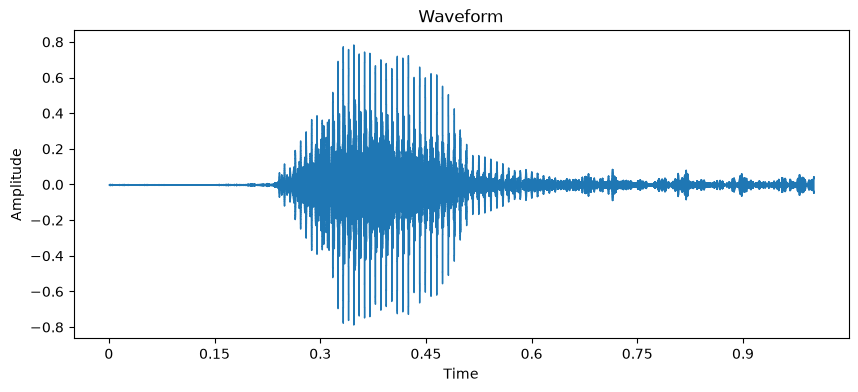

Mean: 1.7812339137890376e-05, Median: 0.00040914781857281923, Variance: 0.008622154593467712


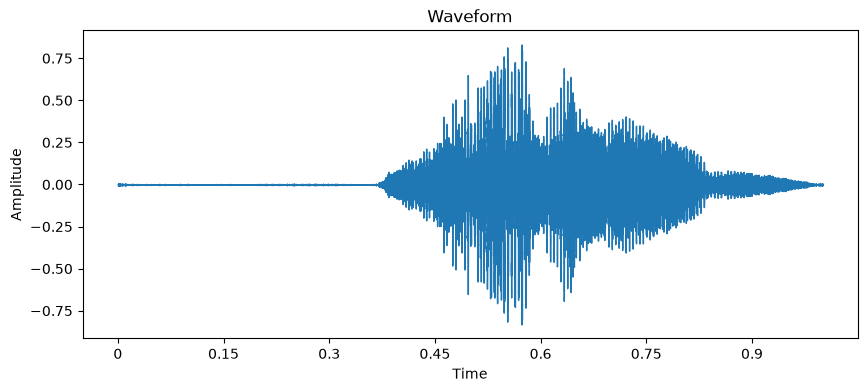

Mean: 6.048574869055301e-05, Median: 5.828906432725489e-05, Variance: 0.014457154087722301


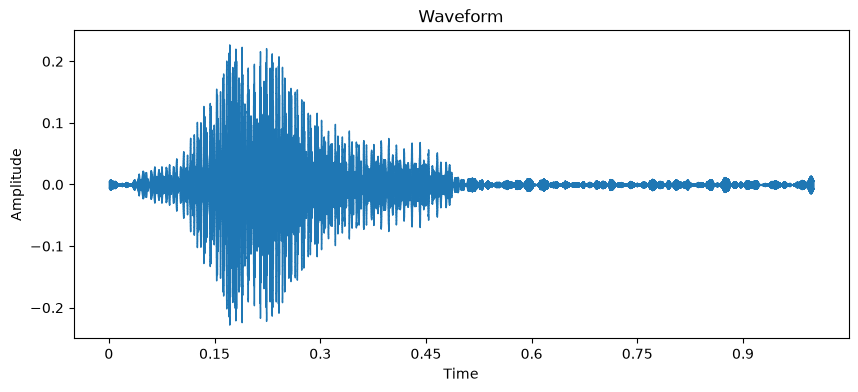

Mean: -8.249750680988654e-05, Median: 0.0007470747223123908, Variance: 0.0014567469479516149


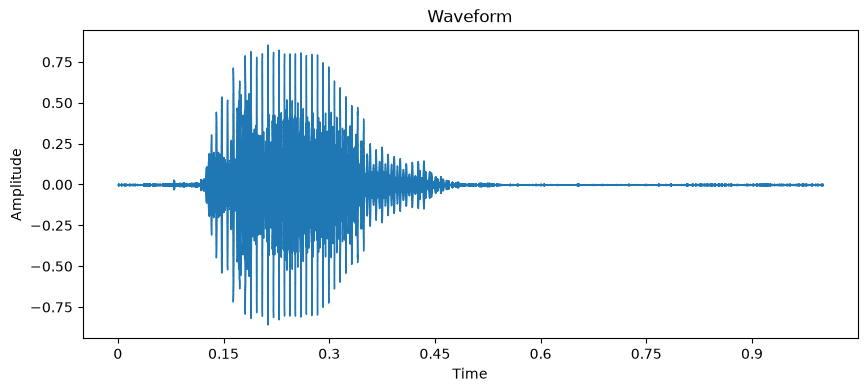

Mean: 1.0973471944453195e-05, Median: -0.0004533413448370993, Variance: 0.01739867404103279


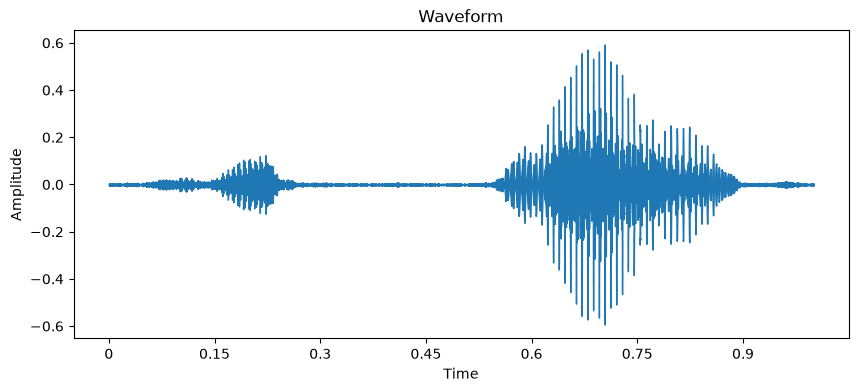

Mean: 8.492547931382433e-05, Median: 0.0005053004715591669, Variance: 0.004348552320152521


In [5]:
listado_muestra= ["data/train/one/b97c9f77_nohash_2.wav",
"data/train/one/c948d727_nohash_3.wav",
"data/train/one/05cf43ef_nohash_0.wav",
"data/train/one/5b09db89_nohash_1.wav",
"data/train/one/8134f43f_nohash_1.wav"]

for muestra in listado_muestra:
    y, sr = librosa.load(muestra)
    plt.figure(figsize=(10, 4))
    librosa.display.waveshow(y, sr=sr)
    plt.title('Waveform')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.show()
    mean = np.mean(y)
    median = np.median(y)
    variance = np.var(y)
    print(f"Mean: {mean}, Median: {median}, Variance: {variance}")

## Preparación
Como son palabras vamos a utilizar algunas herramientas que se relacionan con los fonemas para ver que tal nos va, la idea es armar un dataset con los calculos obtenidos.
Utilizaremos las primeras tres formantes.

F1:  Indica la altura o abertura de la lengua. Es bajo en vocales cerradas como [i, u] y alto en vocales abiertas como [a].

F2:  Indica la posición anterior o posterior de la lengua. Ayuda a distinguir entre vocales palatales (frente) y velares (fondo).

F3:  Aporta matices sobre la forma de los labios y la naturalidad del sonido.

Tambien es muy utilizado:

MFCC: Coeficientes Cepstrales en las Frecuencias Mel, son parámetros que representan la envolvente espectral de una señal de audio y se usan de forma masiva en el reconocimiento de voz y procesamiento de sonido.

In [6]:
# FUNCION DE APOYO PARA GENERAR EL DATASET TABULAR
def generar_dataset_tabular(dir):
  datos = []
  for root, dirs, files in os.walk(dir):
    for file in files:
      # 1. Excluir todo lo que no sea .wav
      if not file.endswith(".wav"):
        continue

      ruta_completa = os.path.join(root, file)

      # 2. Obtener la palabra (nombre de la carpeta contenedora)
      word = os.path.basename(root)
      # excluyo background noise porque son audios mas largo
      if "_background_noise_" in word:
        continue

      if not word=='_unknown_':
        # 3. Parsear el nombre del archivo (ej: f19d1738_nohash_1.wav)
        nombre_base = file[:-4]  # Remueve '.wav'
        if "_nohash_" in nombre_base:
          person, take = nombre_base.split("_nohash_")
        else:
          # Plan de respaldo por si algún archivo tiene otro formato
          partes = nombre_base.split("_nohash_")
          person = partes[0]
          take = partes[-1]
      else: # caso especial de unknown de test
        nombre_base = file[:-8]
        if "_nohash_" in nombre_base:
          word, person, _ ,take = nombre_base.split("_")
        else:
          # Por si algún archivo tiene otro formato
          print("Error en otro formato de nombre")

      # Guardar los datos en una lista de diccionarios
      datos.append(
          {"person": person, "take": take, "word": word, "path": ruta_completa}
      )

  # 4. Crear el DataFrame
  df = pd.DataFrame(datos)
  # Ver los primeros resultados
  print(df.head())
  return df


In [7]:
df_train=generar_dataset_tabular(r"data/train")

     person take word                                  path
0  b97c9f77    2  one  data/train/one/b97c9f77_nohash_2.wav
1  c948d727    3  one  data/train/one/c948d727_nohash_3.wav
2  05cf43ef    0  one  data/train/one/05cf43ef_nohash_0.wav
3  5b09db89    1  one  data/train/one/5b09db89_nohash_1.wav
4  8134f43f    1  one  data/train/one/8134f43f_nohash_1.wav


In [8]:
len(df_train)

105829

In [9]:
df_test = generar_dataset_tabular(r"data/test")

     person take     word                                               path
0  af405b69    0      wow  data/test/_unknown_/wow_af405b69_nohash_0.wav.wav
1  bb05582b    0     zero  data/test/_unknown_/zero_bb05582b_nohash_0.wav...
2  4c6167ca    5  forward  data/test/_unknown_/forward_4c6167ca_nohash_5....
3  f9643d42    2  forward  data/test/_unknown_/forward_f9643d42_nohash_2....
4  91b03183    3    three  data/test/_unknown_/three_91b03183_nohash_3.wa...


In [10]:
len(df_test) # 5%

4890

In [11]:
train_speakers = set(df_train['person'])
test_speakers = set(df_test['person'])

overlap = train_speakers.intersection(test_speakers)

print(f"Hablantes repetidos (mezclados): {len(overlap)}")

Hablantes repetidos (mezclados): 239


In [12]:
# FUNCION DE APOYO PARA CALCULAR METRICAS DE MEL
# con GPU si esta disponible

def calcular_medidas(df,SR=16000):
  # 1. Configurar el dispositivo (CUDA)
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print(f"Calculando MFCCs en: {device}")

  # 2. Definir la transformación de MFCC en PyTorch y enviarla a la GPU
  mfcc_transform = torchaudio.transforms.MFCC(
      sample_rate=SR,
      n_mfcc=13,
      melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
  ).to(device)

  mfcc_lists = []
  f1_list, f2_list, f3_list = [], [], []

  for ruta_completa in df["path"]:
    try:
      # A. Cargar el audio con Librosa (Evita por completo el error de TorchCodec)
      y, sr = librosa.load(ruta_completa, sr=16000)

      # Convertir el array a Tensor de PyTorch y enviarlo a la GPU (CUDA)
      waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

      # B. Calcular MFCCs directamente en la GPU
      mfccs = mfcc_transform(waveform)  # Forma: [1, n_mfcc, tiempo]
      mfccs_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()  # Promedio y vuelta a CPU
      mfcc_lists.append(mfccs_mean)

      # C. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
      y_preemph = librosa.effects.preemphasis(y)
      lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))

      roots = np.roots(lpc_coeffs)
      roots = roots[np.imag(roots) > 0]
      ang = np.angle(roots)
      frequencies = sorted(ang * (sr / (2 * np.pi)))

      f1_list.append(frequencies[0] if len(frequencies) > 0 else np.nan)
      f2_list.append(frequencies[1] if len(frequencies) > 1 else np.nan)
      f3_list.append(frequencies[2] if len(frequencies) > 2 else np.nan)

    except Exception as e:
      print(f"Error procesando {ruta_completa}: {e}")
      mfcc_lists.append([np.nan] * 13)
      f1_list.append(np.nan)
      f2_list.append(np.nan)
      f3_list.append(np.nan)

  # 3. Integrar los resultados al DataFrame original
  df["F1"] = f1_list
  df["F2"] = f2_list
  df["F3"] = f3_list

  mfcc_df = pd.DataFrame(
      mfcc_lists, columns=[f"MFCC_{i}" for i in range(1, 14)]
  )
  df = pd.concat([df.reset_index(drop=True), mfcc_df], axis=1)

  print(df[["person", "word", "F1", "MFCC_1"]].head())
  return df

In [13]:
df_train = calcular_medidas(df_train)
df_test = calcular_medidas(df_test)

Calculando MFCCs en: cuda
     person word          F1      MFCC_1
0  b97c9f77  one  876.743225 -108.427750
1  c948d727  one  964.770569  -91.981880
2  05cf43ef  one  596.072571 -156.440674
3  5b09db89  one  646.626892 -116.872467
4  8134f43f  one  578.075989 -107.512894
Calculando MFCCs en: cuda
     person     word           F1      MFCC_1
0  af405b69      wow  1009.709534 -130.447906
1  bb05582b     zero   158.146027 -107.030243
2  4c6167ca  forward   594.538574 -138.177185
3  f9643d42  forward   813.085510 -149.260422
4  91b03183    three  1816.144165 -141.601135


In [14]:
# guardo el dataset calculado para evitar volver a calcular
ruta_df_train_calculado = f"data/train/dataset_con_metricas.csv"
df_train.to_csv(ruta_df_train_calculado, index=False)

ruta_df_test_calculado = f"data/test/dataset_con_metricas.csv"
df_test.to_csv(ruta_df_test_calculado, index=False)



In [6]:
# leer el dataset calculado para evitar volver a calcular
ruta_df_train_calculado = f"data/train/dataset_con_metricas.csv"
df_train = pd.read_csv(ruta_df_train_calculado)

ruta_df_test_calculado = f"data/test/dataset_con_metricas.csv"
df_test = pd.read_csv(ruta_df_test_calculado)

In [7]:
# FUNCION DE APOYO PARA VERIFICAR NULOS
def verificar_nulos(df):
    # 1. Contar cuántos NaN hay en total en todo el DataFrame
    total_nans = df.isna().sum().sum()
    print(f"Total de valores NaN en el DataFrame: {total_nans}")

    # 2. Ver cuántos NaN hay por cada columna (muestra solo las que tienen alguno)
    nans_por_columna = df.isna().sum()
    print("\nConteo de NaN por columna:")
    print(nans_por_columna[nans_por_columna > 0])

    # 3. Filtrar y ver cuáles filas (audios) tienen valores NaN
    filas_con_nans = df[df.isna().any(axis=1)]

In [8]:
verificar_nulos(df_train)

Total de valores NaN en el DataFrame: 2

Conteo de NaN por columna:
F3    2
dtype: int64


In [9]:
# COMO HAY NULOS Y POCOS ELIMINAMOS
# VAMOS A RESPETAR ESTA ELIMINACION
df_limpio = df_train.dropna().reset_index(drop=True)
df_train = df_limpio.copy()

In [10]:
verificar_nulos(df_test)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [15]:
def graficar_distribucion_clases(conjuntos, titulo="Distribución de clases", figsize=(18, 5)):

    # 1. Contar clases en cada conjunto
    conteos = {
        nombre: pd.Series(etiquetas).value_counts()
        for nombre, etiquetas in conjuntos.items()
    }

    # 2. Unión de clases, ordenadas por frecuencia en el primer conjunto
    todas = sorted(set().union(*[set(c.index) for c in conteos.values()]))
    primero = next(iter(conteos.values()))
    orden = primero.reindex(todas, fill_value=0).sort_values(ascending=False).index.tolist()
    solo_en_otros = [c for c in todas if c not in orden]
    clases = orden + solo_en_otros

    # 3. Matriz de conteos: filas = clases, columnas = conjuntos
    M = pd.DataFrame(
        {nombre: c.reindex(clases, fill_value=0) for nombre, c in conteos.items()},
        index=clases,
    )
    props = M.div(M.sum(axis=0), axis=1)

    # 4. Gráficos
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    M.plot(kind="bar", ax=axes[0], width=0.8, colormap="tab10")
    axes[0].set_title(f"{titulo} — conteos")
    axes[0].set_xlabel("Palabra")
    axes[0].set_ylabel("Cantidad de muestras")
    axes[0].tick_params(axis="x", rotation=90)
    axes[0].grid(axis="y", alpha=0.3)
    axes[0].legend(title="Conjunto")

    props.plot(kind="bar", ax=axes[1], width=0.8, colormap="tab10")
    axes[1].set_title(f"{titulo} — proporción")
    axes[1].set_xlabel("Palabra")
    axes[1].set_ylabel("Proporción dentro del conjunto")
    axes[1].tick_params(axis="x", rotation=90)
    axes[1].grid(axis="y", alpha=0.3)
    axes[1].legend(title="Conjunto")

    plt.tight_layout()
    plt.show()


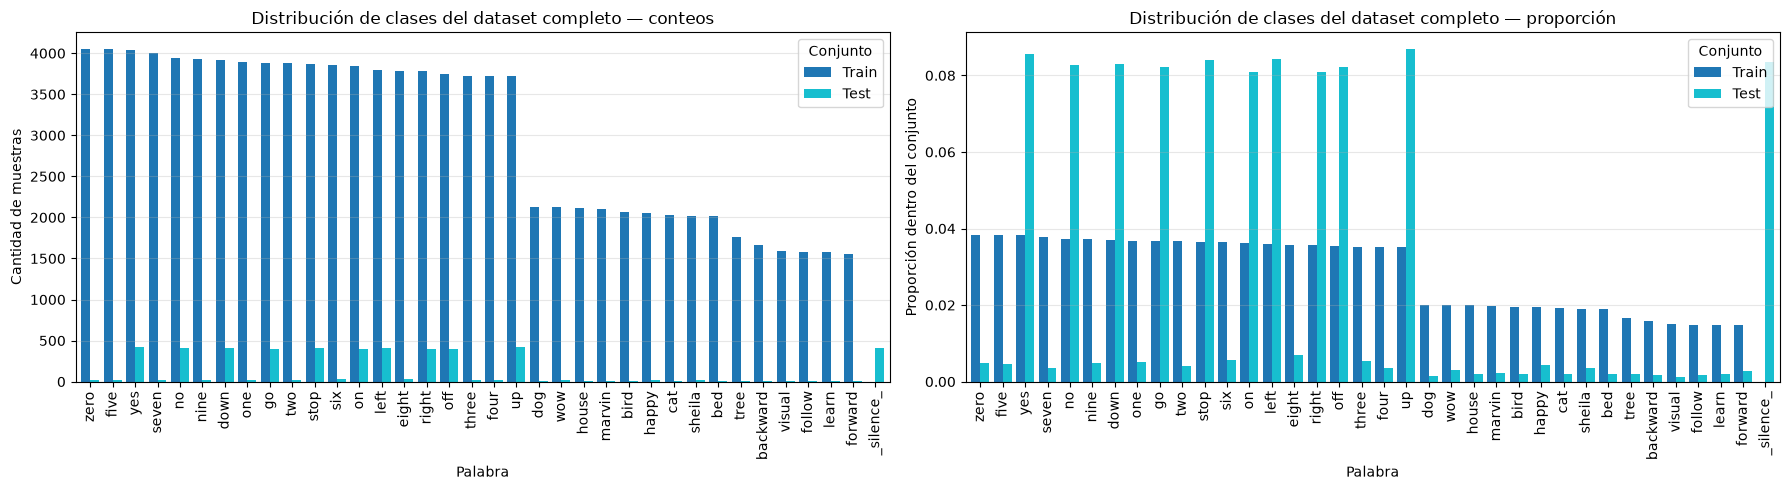

In [21]:
graficar_distribucion_clases(
    {"Train": df_train["word"], "Test": df_test["word"]},
    titulo="Distribución de clases del dataset completo"
)

## 1.x Métrica única: F1-macro

Se usa F1-macro sobre las 35 palabras. El conjunto de test está desbalanceado y `_silence_` no existe en train, por eso se excluye de la métrica principal.


## Utilidades de métricas

El baseline y las redes usan la misma función para calcular F1 macro, F1 ponderado y exactitud.


In [11]:
%%writefile metricas.py
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import accuracy_score, f1_score


def calcular_metricas(y_true, y_pred, labels):
    """Calcula las mismas métricas para el baseline y para las redes."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    labels = list(labels)
    mask = np.isin(y_true, labels)

    return {
        "f1_macro": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_weighted": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            )
        ),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "accuracy_palabras": (
            float(accuracy_score(y_true[mask], y_pred[mask]))
            if mask.any()
            else float("nan")
        ),
    }


def guardar_metricas(ruta, run_id, modelo, params, seg, dev, test=None, extra=None):
    """Guarda las métricas en el mismo formato para todos los modelos."""
    datos = {
        "run_id": run_id,
        "modelo": modelo,
        "params": int(params),
        "seg": float(seg),
    }
    datos.update({f"dev_{k}": v for k, v in dev.items()})
    if test is not None:
        datos.update({f"test_{k}": v for k, v in test.items()})
    if extra:
        datos.update(extra)

    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump(datos, f, indent=2, ensure_ascii=False)

    return datos


Overwriting metricas.py


## Baseline Etapa 1

Ya con este dataset formado y caracteristicas calculadas probamos regression logistica

In [12]:

y_tr = df_train["word"]
columnas_a_excluir = ["person", "take", "word"] # el path lo conservamos hasta luego del split
X_tr = df_train.drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])

y_te = df_test["word"]
X_te = df_test.drop(columns=[col for col in columnas_a_excluir if col in df_test.columns])

print(f"Tamaño total del dataset de train: {X_tr.shape} audios con {X_tr.shape[1]-1} características.") # restamos path

print(f"Tamaño total del dataset de test: {X_te.shape} audios con {X_te.shape[1]-1} características.") # restamos path

Tamaño total del dataset de train: (105827, 17) audios con 16 características.
Tamaño total del dataset de test: (4890, 17) audios con 16 características.


In [13]:
# 1. Partición de Datos (Estrategia Train / Dev / Test)
# Primero separamos el Train (80%) del resto (20%)
# Los datos finales de test separados ya en la descarga del dataset representan un 5% del train
X_train, X_dev, y_train, y_dev = train_test_split(X_tr, y_tr, test_size=0.20, random_state=42, stratify=y_tr) #separamos asi para poder tener el mismo conjunto
X_test, y_test = X_te, y_te
# para la etapa 2 que se planteó en clase de audio (espectrograma)
X_train_path=X_train.pop('path') # conservamos y quitamos el path de X
X_dev_path=X_dev.pop('path')
X_test_path=X_test.pop('path')


# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)
print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")
print(f"Datos de Entrenamiento (Test): {X_test.shape}")

Datos de Entrenamiento (Train): (84661, 16)
Datos de Desarrollo (Dev): (21166, 16)
Datos de Entrenamiento (Test): (4890, 16)


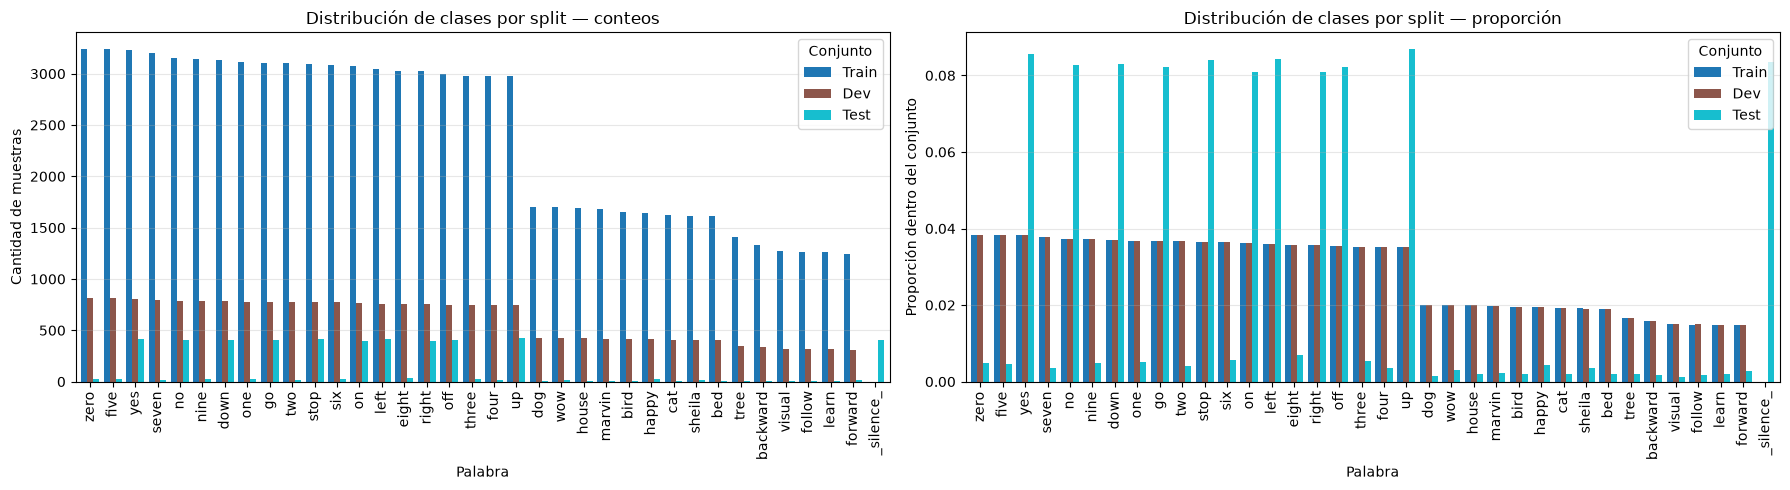

In [16]:
graficar_distribucion_clases(
    {"Train": y_train, "Dev": y_dev, "Test": y_test},
    titulo="Distribución de clases por split"
)

In [25]:
X_train.keys()

Index(['F1', 'F2', 'F3', 'MFCC_1', 'MFCC_2', 'MFCC_3', 'MFCC_4', 'MFCC_5',
       'MFCC_6', 'MFCC_7', 'MFCC_8', 'MFCC_9', 'MFCC_10', 'MFCC_11', 'MFCC_12',
       'MFCC_13'],
      dtype='str')

In [ ]:
from metricas import calcular_metricas, guardar_metricas

# 3. Construcción del Modelo Base (Baseline) con features básicas
t0 = time.time()
modelo_logreg_basico = LogisticRegression(C=1, max_iter=200, verbose=1, random_state=42)
modelo_logreg_basico.fit(X_train_scaled, y_train)
seg_logreg_basico = time.time() - t0

# Guardamos las features de test de este baseline para la evaluación final
X_test_scaled_basico = X_test_scaled.copy()

metricas_dev_basico = calcular_metricas(
    y_dev,
    modelo_logreg_basico.predict(X_dev_scaled),
    modelo_logreg_basico.classes_,
)
guardar_metricas(
    DIR_RESULTADOS / "logreg_basico" / "metricas.json",
    run_id="logreg_basico",
    modelo="logreg",
    params=modelo_logreg_basico.coef_.size,
    seg=seg_logreg_basico,
    dev=metricas_dev_basico,
    extra={"features": "basicas"},
)
print("Baseline básico — Dev:", metricas_dev_basico)


Baseline básico — Dev: {'f1_macro': 0.2408651853325114, 'f1_weighted': 0.25038291752153363, 'accuracy': 0.2598507039591798, 'accuracy_palabras': 0.2598507039591798}


In [29]:
from sklearn.linear_model import LogisticRegressionCV

# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

Mejor valor de C encontrado: 1.0
Precisión con el mejor C: 0.2598


No mejora demasiado vamos a ir por otro intento sumando algunos coeficientes para ver de capturar los cambios en fonemas compuestos.

Agregando la desviacion estandar en los coeficientes de mel y tambien deltas (derivadas temporales de primer y segundo orden)

In [30]:
# FUNCION DE APOYO PARA CALCULO DE METRICAS EXTENDIDAS
def calcular_medidas_extendidas(df,SR=16000):
  # Forzar backend de sonido si es necesario
  try:
    torchaudio.set_audio_backend("soundfile")
  except:
    pass

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  print(f"Procesando características avanzadas en: {device}")

  # Transformaciones en PyTorch/TorchAudio
  mfcc_transform = torchaudio.transforms.MFCC(
      sample_rate=SR,
      n_mfcc=13,
      melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23},
  ).to(device)

  delta_transform = torchaudio.transforms.ComputeDeltas().to(device)

  datos_procesados = []

  for ruta_completa in df["path"]:
    try:
      # 1. Cargar audio con Librosa y enviar a PyTorch/CUDA
      y, sr = librosa.load(ruta_completa, sr=16000)
      waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0).to(device)

      # 2. Calcular MFCCs [1, 13, tiempo]
      mfccs = mfcc_transform(waveform)

      # 3. Calcular Deltas (velocidad) y Delta-Deltas (aceleración) de los MFCCs
      mfccs_delta = delta_transform(mfccs)
      mfccs_delta2 = delta_transform(mfccs_delta)

      # 4. Extraer estadísticas temporales para cada uno (Media y Desviación Estándar)
      # Esto resume la dinámica temporal en un vector fijo por cada audio
      mfcc_mean = mfccs.mean(dim=-1).squeeze(0).cpu().numpy()
      mfcc_std = mfccs.std(dim=-1).squeeze(0).cpu().numpy()

      delta_mean = mfccs_delta.mean(dim=-1).squeeze(0).cpu().numpy()
      delta_std = mfccs_delta.std(dim=-1).squeeze(0).cpu().numpy()

      delta2_mean = mfccs_delta2.mean(dim=-1).squeeze(0).cpu().numpy()
      delta2_std = mfccs_delta2.std(dim=-1).squeeze(0).cpu().numpy()

      # 5. Cálculo de Formantes (F1, F2, F3) usando LPC en CPU
      y_preemph = librosa.effects.preemphasis(y)
      lpc_coeffs = librosa.lpc(y_preemph, order=int(sr / 2000 + 2))
      roots = np.roots(lpc_coeffs)
      roots = roots[np.imag(roots) > 0]
      ang = np.angle(roots)
      frequencies = sorted(ang * (sr / (2 * np.pi)))

      f1 = frequencies[0] if len(frequencies) > 0 else np.nan
      f2 = frequencies[1] if len(frequencies) > 1 else np.nan
      f3 = frequencies[2] if len(frequencies) > 2 else np.nan

      # Estructura base de la fila con metadatos y formantes
      fila = {
          "person": df.loc[df["path"] == ruta_completa, "person"].values[0],
          "take": df.loc[df["path"] == ruta_completa, "take"].values[0],
          "word": df.loc[df["path"] == ruta_completa, "word"].values[0],
          "F1": f1,
          "F2": f2,
          "F3": f3,
      }

      # Agregar dinámicamente las columnas al diccionario
      for i in range(13):
        fila[f"MFCC_{i+1}_mean"] = mfcc_mean[i]
        fila[f"MFCC_{i+1}_std"] = mfcc_std[i]
        fila[f"Delta_{i+1}_mean"] = delta_mean[i]
        fila[f"Delta_{i+1}_std"] = delta_std[i]
        fila[f"Delta2_{i+1}_mean"] = delta2_mean[i]
        fila[f"Delta2_{i+1}_std"] = delta2_std[i]

      fila["path"] = ruta_completa
      datos_procesados.append(fila)

    except Exception as e:
      print(f"Error procesando {ruta_completa}: {e}")

  # Reconstruir el DataFrame completo con las nuevas características enriquecidas
  df_enriquecido = pd.DataFrame(datos_procesados)
  return df_enriquecido



In [31]:
df_train = calcular_medidas_extendidas(df_train)
df_test = calcular_medidas_extendidas(df_test)

Procesando características avanzadas en: cuda
Procesando características avanzadas en: cuda


In [32]:

# guardo el dataset calculado para evitar volver a calcular
ruta_df_train_ext_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_train.to_csv(ruta_df_train_ext_calculado, index=False)
ruta_df_test_ext_calculado = f"data/test/dataset_con_metricas_std+deltas.csv"
df_test.to_csv(ruta_df_test_ext_calculado, index=False)

In [18]:

# leer el dataset calculado para evitar volver a calcular
ruta_df_train_ext_calculado = f"data/train/dataset_con_metricas_std+deltas.csv"
df_train = pd.read_csv(ruta_df_train_ext_calculado)
ruta_df_test_ext_calculado = f"data/test/dataset_con_metricas_std+deltas.csv"
df_test = pd.read_csv(ruta_df_test_ext_calculado)


In [19]:
verificar_nulos(df_train)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [35]:
verificar_nulos(df_test)

Total de valores NaN en el DataFrame: 0

Conteo de NaN por columna:
Series([], dtype: int64)


In [20]:
# Reemplazar el antiguo df por el enriquecido
X_train = pd.merge(X_train_path.copy(), df_train, on="path", how="left")
X_dev = pd.merge(X_dev_path.copy(), df_train, on="path", how="left")


In [21]:

columnas_a_excluir = ["person", "take", "word","path"]
X_train = X_train.copy().drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])
X_dev = X_dev.copy().drop(columns=[col for col in columnas_a_excluir if col in df_train.columns])
X_test = df_test.copy().drop(columns=[col for col in columnas_a_excluir if col in df_test.columns])

# 2. Escalar los datos (fundamental para que converjan los coeficientes de audio)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_dev_scaled = scaler.transform(X_dev)
X_test_scaled = scaler.transform(X_test)
print(f"Datos de Entrenamiento (Train): {X_train.shape}")
print(f"Datos de Desarrollo (Dev): {X_dev.shape}")
print(f"Datos de Entrenamiento (Test): {X_test.shape}")



Datos de Entrenamiento (Train): (84661, 81)
Datos de Desarrollo (Dev): (21166, 81)
Datos de Entrenamiento (Test): (4890, 81)


In [ ]:
# 3. Construcción del Modelo Base (Baseline) con features extendidas
t0 = time.time()
modelo_logreg_extendido = LogisticRegression(C=1, max_iter=200, verbose=1, random_state=42)
modelo_logreg_extendido.fit(X_train_scaled, y_train)
seg_logreg_extendido = time.time() - t0

# Mantenemos modelo_base para el análisis de errores
modelo_base = modelo_logreg_extendido

metricas_dev_extendido = calcular_metricas(
    y_dev,
    modelo_logreg_extendido.predict(X_dev_scaled),
    modelo_logreg_extendido.classes_,
)
guardar_metricas(
    DIR_RESULTADOS / "logreg_extendido" / "metricas.json",
    run_id="logreg_extendido",
    modelo="logreg",
    params=modelo_logreg_extendido.coef_.size,
    seg=seg_logreg_extendido,
    dev=metricas_dev_extendido,
    extra={"features": "extendidas"},
)
print("Baseline extendido — Dev:", metricas_dev_extendido)


Baseline extendido — Dev: {'f1_macro': 0.568225244838158, 'f1_weighted': 0.5742558318690002, 'accuracy': 0.5760653878862326, 'accuracy_palabras': 0.5760653878862326}


In [41]:
# Busca el mejor 'C' entre una lista de opciones usando validación cruzada (cv=5)
modelo_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    penalty="l2",
    solver="lbfgs",
    max_iter=300,
    random_state=42,
)

# Entrenar el modelo optimizado
modelo_cv.fit(X_train_scaled, y_train)

# Ver cuál fue el mejor valor de C que eligió automáticamente
print(f"Mejor valor de C encontrado: {modelo_cv.C_[0]}")
print(f"Precisión con el mejor C: {modelo_cv.score(X_dev_scaled, y_dev):.4f}")

/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/juan/miniconda3/envs/speech_cmd/lib/python3.11/site-packages/sklearn/linear_model/_logistic

Mejor valor de C encontrado: 100.0
Precisión con el mejor C: 0.5756


### Interpretación de la métrica

<!-- Escribir acá la interpretación -->


# Etapa 2 — MLP sobre espectrogramas, regularización y errores

<!-- Descripción de la etapa: completar -->



# De la señal al espectrograma

In [42]:
def leer_audio(path):
    audio_bin = tf.io.read_file(path)
    waveform, sr = tf.audio.decode_wav(audio_bin, desired_channels=1)
    return waveform.numpy()[:, 0], int(sr.numpy())

labels, speakers, waves, rates = [], [], [], []
listado_audios = pd.concat([X_train_path,X_dev_path,X_test_path], axis=0, ignore_index=True)
for f in listado_audios:
    w, sr = leer_audio(f)
    waves.append(w)
    rates.append(sr)


print("Frecuencias de muestreo encontradas:", set(rates))
print(f"Duración promedio: {np.mean([len(w) for w in waves]) / rates[0]:.3f} s")

W0000 00:00:1794511397.100400 1567412 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1794511397.103261 1567412 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2554 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


Frecuencias de muestreo encontradas: {16000}
Duración promedio: 0.982 s


In [43]:
SR = 16000 # aca mantenemos 16000 porque en el baseline usamos ese sample_rate
N_MAX = SR  # clips de 1 segundo
FRAME_LENGTH = 512 # ventana de 32 ms en 16Khz
FRAME_STEP = 256  # salto de 16 ms en 16Khz
BATCH_SIZE_GEN = 128

def ajustar_largo(w, n=N_MAX):
    w = w[:n]
    return np.pad(w, (0, n - len(w)))

def extraer_espectrograma(waves_batch):
    stft = tf.signal.stft(
        waves_batch,
        frame_length=FRAME_LENGTH,
        frame_step=FRAME_STEP,
        fft_length=FRAME_LENGTH,
    )
    return tf.math.log(tf.abs(stft) + 1e-6)[..., tf.newaxis].numpy()

# --- Procesamiento y Escritura Directa a Disco ---

#FUNCION DE GENERACION DE ESPECTROGRAMAS

def generar_espectrogramas(listado_rutas, ruta_salida):
    with h5py.File(ruta_salida, "w") as hf:
        dataset_x = None  # Lo inicializaremos con el primer lote

        for i in range(0, len(listado_rutas), BATCH_SIZE_GEN):
            lote_rutas = listado_rutas[i:i + BATCH_SIZE_GEN]
            waves_batch = []

            # 1. Cargar y procesar audios del lote
            for ruta in lote_rutas:
                w_orig, sr_orig = librosa.load(ruta, sr=None)
                if sr_orig != SR:
                    w_orig = librosa.resample(w_orig, orig_sr=sr_orig, target_sr=SR)
                waves_batch.append(ajustar_largo(w_orig))

            X_wave_lote = np.stack(waves_batch).astype(np.float32)
            spec_lote = extraer_espectrograma(X_wave_lote)

            # 2. Guardar en el HDF5
            if dataset_x is None:
                # Si es el primer lote, creamos el "molde" en el archivo
                forma_base = spec_lote.shape[1:]  # (tiempo, frecuencia, canal)
                # maxshape con 'None' permite que el dataset crezca infinitamente hacia abajo
                dataset_x = hf.create_dataset("X_spec", shape=(0, *forma_base),
                                            maxshape=(None, *forma_base),
                                            dtype='float32', compression="gzip")

            # Agrandamos el archivo en disco para que entre el nuevo lote
            dataset_x.resize(dataset_x.shape[0] + spec_lote.shape[0], axis=0)
            # Pegamos los datos del lote en las nuevas filas generadas
            dataset_x[-spec_lote.shape[0]:] = spec_lote

            print(f"Procesados y guardados: {dataset_x.shape[0]} / {len(listado_rutas)}")

        # 3. Guardar las rutas para auditar que el orden coincide con las etiquetas
        hf.create_dataset(
            "paths",
            data=np.asarray([str(ruta) for ruta in listado_rutas], dtype=h5py.string_dtype()),
        )

    print(f"Guardado {ruta_salida}: {len(listado_rutas)} espectrogramas")

#TRAIN
generar_espectrogramas(X_train_path, r"data/X_train_spec.h5")
# DEV
generar_espectrogramas(X_dev_path, r"data/X_dev_spec.h5")
# TEST
generar_espectrogramas(X_test_path, r"data/X_test_spec.h5")


Procesados y guardados: 128 / 84661
Procesados y guardados: 256 / 84661
Procesados y guardados: 384 / 84661
Procesados y guardados: 512 / 84661
Procesados y guardados: 640 / 84661
Procesados y guardados: 768 / 84661
Procesados y guardados: 896 / 84661
Procesados y guardados: 1024 / 84661
Procesados y guardados: 1152 / 84661
Procesados y guardados: 1280 / 84661
Procesados y guardados: 1408 / 84661
Procesados y guardados: 1536 / 84661
Procesados y guardados: 1664 / 84661
Procesados y guardados: 1792 / 84661
Procesados y guardados: 1920 / 84661
Procesados y guardados: 2048 / 84661
Procesados y guardados: 2176 / 84661
Procesados y guardados: 2304 / 84661
Procesados y guardados: 2432 / 84661
Procesados y guardados: 2560 / 84661
Procesados y guardados: 2688 / 84661
Procesados y guardados: 2816 / 84661
Procesados y guardados: 2944 / 84661
Procesados y guardados: 3072 / 84661
Procesados y guardados: 3200 / 84661
Procesados y guardados: 3328 / 84661
Procesados y guardados: 3456 / 84661
Procesad

In [44]:
df_test.value_counts('word')

word
up           425
yes          419
left         412
stop         411
_silence_    408
down         406
no           405
go           402
off          402
right        396
on           396
eight         34
six           28
three         26
one           25
zero          24
nine          24
five          23
happy         21
two           20
seven         18
four          18
sheila        17
wow           15
forward       13
marvin        11
bed           10
tree          10
cat           10
house         10
bird          10
learn         10
backward       9
follow         9
dog            7
visual         6
Name: count, dtype: int64

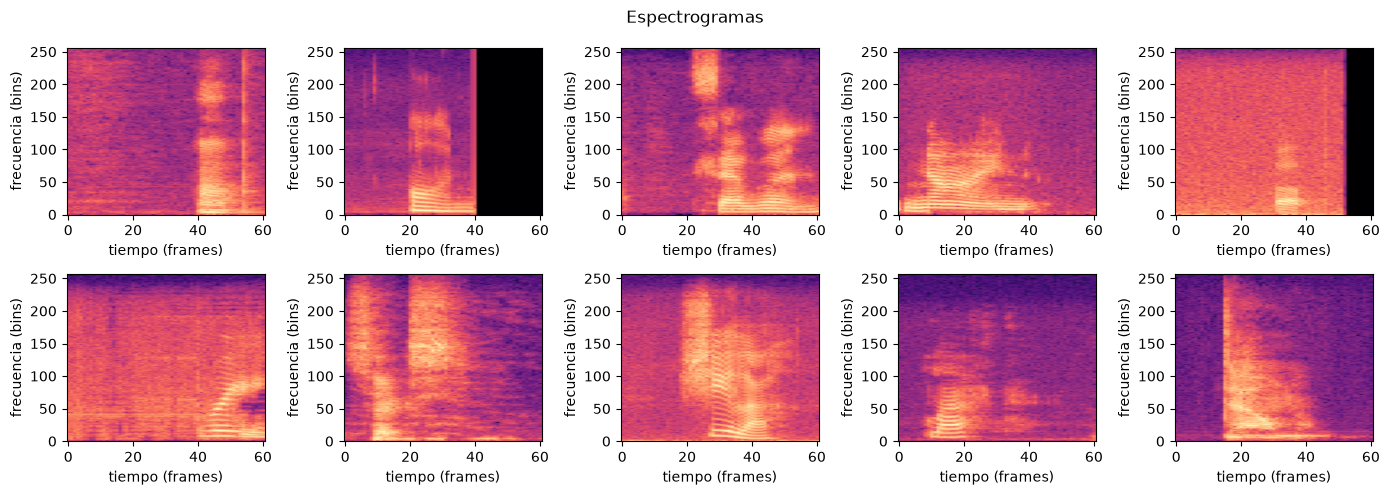

In [45]:
# 1. Abrimos el archivo en modo lectura ("r")
with h5py.File(r"data/X_train_spec.h5", "r") as hf:
    
    # Referencia al archivo en el disco
    X_disco = hf["X_spec"]
    
    # Extraemos solo los primeros 10 espectrogramas a la memoria RAM
    X_spec_lote = X_disco[0:10]

# 2. Tu código exacto, pero usando el lote que acabamos de extraer
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for d, ax in enumerate(axes.ravel()):
    i = d
    # Usamos X_spec_lote en lugar de cargar todo el dataset original
    ax.imshow(X_spec_lote[i, :, :, 0].T, origin="lower", aspect="auto", cmap="magma")
    # ax.set_title(f"Muestra {d}")
    ax.set_xlabel("tiempo (frames)")
    ax.set_ylabel("frecuencia (bins)")

plt.suptitle("Espectrogramas")
plt.tight_layout()
plt.show()

In [46]:
# A. Codificar etiquetas unificando el vocabulario para evitar errores (como _silence_)
le = LabelEncoder()
todas_las_etiquetas = pd.concat([y_train, y_dev, df_test['word']])
le.fit(todas_las_etiquetas)

y_tr_num = le.transform(y_train)
y_va_num = le.transform(y_dev)
y_te_num = le.transform(y_test)
print("Clases totales detectadas:", len(le.classes_))

num_classes=len(le.classes_)

# B. Calcular media y std SOLO de Train, por lotes para no cargar todo en RAM
def calcular_media_std_hdf5(h5_path, por_lote=256):
    suma = 0.0
    suma_cuadrados = 0.0
    cantidad = 0
    with h5py.File(h5_path, "r") as hf:
        dset = hf["X_spec"]
        forma = dset.shape[1:]
        for i in range(0, dset.shape[0], por_lote):
            lote = dset[i:i + por_lote].astype(np.float64)
            suma += lote.sum()
            suma_cuadrados += np.square(lote).sum()
            cantidad += lote.size
    mu = suma / cantidad
    varianza = max(suma_cuadrados / cantidad - mu ** 2, 0.0)
    return mu, float(np.sqrt(varianza)), forma

print("Calculando media y std de Train por lotes...")
mu, sd, INPUT_SHAPE = calcular_media_std_hdf5(r"data/X_train_spec.h5")
print(f"Media: {mu:.4f} | Std: {sd:.4f}")
print("Forma de entrada:", INPUT_SHAPE)


Clases totales detectadas: 36
Calculando media y std de Train por lotes...
Media: -5.1619 | Std: 2.7910
Forma de entrada: (61, 257, 1)


## 2.x Archivos preprocesados y reproducibilidad

Se guardan los splits, las etiquetas codificadas y la normalización para poder retomar el trabajo sin recalcular todo.


In [47]:
import json
import numpy as np

np.savez_compressed(
    PREPROCESADOS / "split.npz",
    y_tr_num=y_tr_num,
    y_va_num=y_va_num,
    y_te_num=y_te_num,
    train_paths=X_train_path.to_numpy(),
    dev_paths=X_dev_path.to_numpy(),
    test_paths=X_test_path.to_numpy(),
)
with open(PREPROCESADOS / "norm.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "mu": float(mu),
            "sd": float(sd),
            "input_shape": list(INPUT_SHAPE),
            "classes": list(le.classes_),
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

def cargar_preprocesados():
    z = np.load(PREPROCESADOS / "split.npz", allow_pickle=True)
    with open(PREPROCESADOS / "norm.json", encoding="utf-8") as f:
        norm = json.load(f)
    return z, norm

print("Guardado en", PREPROCESADOS)


Guardado en /home/juan/workdir/speech_commands/preprocesados


### Interpretación

<!-- Escribir acá la interpretación -->


## 2.x Scripts de entrenamiento

Estas celdas escriben en disco los tres archivos que usa el subproceso: `datos.py`, `modelos.py` y `train_model.py`. Si se modifica una red, se edita la celda de `modelos.py` y se vuelve a ejecutar.


In [48]:
%%writefile datos.py
import json
from pathlib import Path
import numpy as np
import h5py
import tensorflow as tf


class GeneradorLotesHDF5(tf.keras.utils.Sequence):
    def __init__(self, h5_path, etiquetas, batch_size, mu, sd, rutas_esperadas=None):
        super().__init__()
        self.h5_path = h5_path
        self.etiquetas = np.asarray(etiquetas)
        self.batch_size = batch_size
        self.mu = mu
        self.sd = sd

        with h5py.File(self.h5_path, "r") as hf:
            self.num_samples = hf["X_spec"].shape[0]
            if rutas_esperadas is not None:
                if "paths" not in hf:
                    raise ValueError(f"{self.h5_path} no tiene el dataset 'paths'.")
                rutas_h5 = [
                    p.decode() if isinstance(p, bytes) else str(p)
                    for p in hf["paths"][:]
                ]
                rutas_esperadas = [str(r) for r in rutas_esperadas]
                if rutas_h5 != rutas_esperadas:
                    raise ValueError(
                        f"{self.h5_path}: las rutas no coinciden con las etiquetas."
                    )

        if len(self.etiquetas) != self.num_samples:
            raise ValueError(
                f"{self.h5_path}: hay {self.num_samples} espectrogramas "
                f"pero {len(self.etiquetas)} etiquetas."
            )

    def __len__(self):
        return int(np.ceil(self.num_samples / self.batch_size))

    def __getitem__(self, i):
        start = i * self.batch_size
        end = min((i + 1) * self.batch_size, self.num_samples)

        with h5py.File(self.h5_path, "r") as hf:
            X_lote = hf["X_spec"][start:end]

        X_lote = (X_lote - self.mu) / self.sd
        return X_lote, self.etiquetas[start:end]


def crear_generadores(base_dir, batch_size=128):
    base_dir = Path(base_dir)
    z = np.load(base_dir / "preprocesados" / "split.npz", allow_pickle=True)
    with open(base_dir / "preprocesados" / "norm.json", encoding="utf-8") as f:
        norm = json.load(f)

    mu, sd = norm["mu"], norm["sd"]
    data = base_dir / "data"

    train_gen = GeneradorLotesHDF5(
        data / "X_train_spec.h5", z["y_tr_num"], batch_size, mu, sd,
        rutas_esperadas=z["train_paths"],
    )
    dev_gen = GeneradorLotesHDF5(
        data / "X_dev_spec.h5", z["y_va_num"], batch_size, mu, sd,
        rutas_esperadas=z["dev_paths"],
    )
    test_gen = GeneradorLotesHDF5(
        data / "X_test_spec.h5", z["y_te_num"], batch_size, mu, sd,
        rutas_esperadas=z["test_paths"],
    )
    return train_gen, dev_gen, test_gen, norm


Overwriting datos.py


In [49]:
%%writefile modelos.py
# Redes del TP. Editar esta celda y ejecutarla para guardar modelos.py.
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

NUM_CLASSES = 36
num_classes = NUM_CLASSES

def bloque_conv_2d(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
    ]

def bloque_conv_bn(filtros):
    return [
        layers.Conv2D(filtros, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
    ]

def nivel0_mlp(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N0_MLP")

def nivel1_cnn_minima(input_shape):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(8, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N1_CNN_minima")

def nivel2_cnn(input_shape, cabezal="flatten"):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32):
        capas += bloque_conv_2d(f)
    capas += [layers.Conv2D(64, (3, 3), activation="relu", padding="same")]
    if cabezal == "flatten":
        capas += [layers.MaxPooling2D((2, 2)), layers.Flatten()]
    else:
        capas += [layers.GlobalAveragePooling2D()]
    capas += [layers.Dense(64, activation="relu"),
              layers.Dropout(0.3),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name=f"N2_{cabezal}")

def nivel2_cnn_gap(input_shape):
    return nivel2_cnn(input_shape, "gap")

def nivel3_cnn_regularizada(input_shape):
    capas = [layers.Input(shape=input_shape)]
    for f in (16, 32, 64):
        capas += bloque_conv_bn(f)
    capas += [layers.Flatten(),
              layers.Dense(64, activation="relu"),
              layers.Dropout(0.4),
              layers.Dense(num_classes, activation="softmax")]
    return models.Sequential(capas, name="N3_CNN_regularizada")

def nivel4_crnn(input_shape):
    T = input_shape[0] // 4   # tiempo después de dos pools de 2
    F = input_shape[1] // 4   # frecuencia después de dos pools de 2
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Reshape((T, F * 32)),   # secuencia de T pasos, cada uno con F*32 valores
        layers.GRU(64),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ], name="N4_CRNN")

MODELOS = {
    "n0_mlp": nivel0_mlp,
    "n1_cnn_min": nivel1_cnn_minima,
    "n2_cnn": nivel2_cnn,
    "n2_gap": nivel2_cnn_gap,
    "n3_cnn": nivel3_cnn_regularizada,
    "n4_crnn": nivel4_crnn,
}


Overwriting modelos.py


In [50]:
%%writefile train_model.py
"""Entrenamiento de un modelo individual.

Este script se ejecuta como subproceso desde el notebook. Al terminar,
el proceso muere y libera la memoria de GPU.

Uso:
    python train_model.py --modelo n4_crnn --batch 128 --lr 3e-4 \
        --run-id prueba_crnn --epochs 60

Para evaluar un modelo ya entrenado:
    python train_model.py --modelo n4_crnn --run-id prueba_crnn \
        --evaluate-only --test
"""

import argparse
import gc
import json
import os
import sys
import time
from pathlib import Path

# Debe configurarse antes de importar TensorFlow.
os.environ.setdefault("TF_GPU_ALLOCATOR", "cuda_malloc_async")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import callbacks
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

BASE_DIR = Path(os.environ.get("TP_BASE_DIR", Path(__file__).resolve().parent))
sys.path.insert(0, str(BASE_DIR))

from datos import crear_generadores
from metricas import calcular_metricas, guardar_metricas
from modelos import MODELOS


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--modelo", required=True, choices=sorted(MODELOS))
    p.add_argument("--batch", type=int, default=128)
    p.add_argument("--lr", type=float, default=3e-4)
    p.add_argument("--epochs", type=int, default=60)
    p.add_argument("--run-id", required=True)
    p.add_argument("--test", action="store_true")
    p.add_argument("--evaluate-only", action="store_true")
    p.add_argument("--seed", type=int, default=42)
    return p.parse_args()


def predecir(modelo, generador):
    """Devuelve y_true e y_pred para un generador completo."""
    y_true, y_pred = [], []
    for i in range(len(generador)):
        xb, yb = generador[i]
        y_pred.append(modelo.predict_on_batch(xb).argmax(axis=1))
        y_true.append(yb)
    return np.concatenate(y_true), np.concatenate(y_pred)


def guardar_reporte(y_true, y_pred, clases, labels_palabras, out, prefijo="dev"):
    target_names = [clases[i] for i in labels_palabras]
    reporte = classification_report(
        y_true,
        y_pred,
        labels=labels_palabras,
        target_names=target_names,
        zero_division=0,
    )
    (out / f"classification_report_{prefijo}.txt").write_text(
        reporte, encoding="utf-8"
    )

    cm = confusion_matrix(y_true, y_pred, labels=labels_palabras)
    fig, ax = plt.subplots(figsize=(12, 10))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
    ax.set_title(f"Matriz de confusión ({prefijo})")
    plt.tight_layout()
    fig.savefig(out / f"confusion_matrix_{prefijo}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)


def main():
    args = parse_args()
    tf.keras.utils.set_random_seed(args.seed)
    np.random.seed(args.seed)

    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass

    base_dir = BASE_DIR
    resultados = base_dir / "resultados"
    out = resultados / args.run_id
    out.mkdir(parents=True, exist_ok=True)

    train_gen, dev_gen, test_gen, norm = crear_generadores(
        base_dir=base_dir,
        batch_size=args.batch,
    )

    clases = list(norm["classes"])
    num_classes = len(clases)
    labels_palabras = [i for i, c in enumerate(clases) if c != "_silence_"]

    modelo = MODELOS[args.modelo](tuple(norm["input_shape"]))

    with open(out / "summary.txt", "w", encoding="utf-8") as f:
        modelo.summary(print_fn=lambda x: f.write(x + "\n"))

    hist = None
    seg = 0.0
    if not args.evaluate_only:
        modelo.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=args.lr),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"],
        )
        callbacks_list = [
            callbacks.EarlyStopping(
                monitor="val_loss", patience=7, restore_best_weights=True
            ),
            callbacks.ReduceLROnPlateau(
                monitor="val_loss", factor=0.5, patience=3, verbose=1
            ),
            callbacks.CSVLogger(str(out / "historia.csv")),
            callbacks.ModelCheckpoint(
                str(out / "mejor.weights.h5"),
                monitor="val_loss",
                save_best_only=True,
                save_weights_only=True,
            ),
        ]
        t0 = time.time()
        hist = modelo.fit(
            train_gen,
            validation_data=dev_gen,
            epochs=args.epochs,
            callbacks=callbacks_list,
            verbose=2,
        )
        seg = time.time() - t0
    else:
        pesos = out / "mejor.weights.h5"
        if not pesos.exists():
            raise FileNotFoundError(f"No se encontró {pesos}")
        modelo.load_weights(str(pesos))

    # Evaluación en Dev
    y_true_dev, y_pred_dev = predecir(modelo, dev_gen)
    metricas_dev = calcular_metricas(y_true_dev, y_pred_dev, labels_palabras)
    guardar_reporte(y_true_dev, y_pred_dev, clases, labels_palabras, out, "dev")

    if hist is not None:
        pd.DataFrame(hist.history).to_csv(out / "historia.csv", index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(hist.history["loss"], label="train")
        axes[0].plot(hist.history["val_loss"], label="validación")
        axes[0].set_title("Pérdida")
        axes[0].set_xlabel("época")
        axes[0].legend()
        axes[1].plot(hist.history["accuracy"], label="train")
        axes[1].plot(hist.history["val_accuracy"], label="validación")
        axes[1].set_title("Exactitud")
        axes[1].set_xlabel("época")
        axes[1].legend()
        plt.tight_layout()
        fig.savefig(out / "curvas.png", dpi=150, bbox_inches="tight")
        plt.close(fig)

    # Test: solo cuando se pide explícitamente.
    metricas_test = None
    if args.test:
        y_true_test, y_pred_test = predecir(modelo, test_gen)
        metricas_test = calcular_metricas(y_true_test, y_pred_test, labels_palabras)
        guardar_reporte(y_true_test, y_pred_test, clases, labels_palabras, out, "test")

    nombre = "metricas_test.json" if args.evaluate_only else "metricas.json"
    datos = guardar_metricas(
        out / nombre,
        run_id=args.run_id,
        modelo=args.modelo,
        params=modelo.count_params(),
        seg=seg,
        dev=metricas_dev,
        test=metricas_test,
        extra={
            "batch": args.batch,
            "lr": args.lr,
            "seed": args.seed,
            "epocas_entrenadas": int(len(hist.history["loss"])) if hist else None,
        },
    )

    print(json.dumps(datos, indent=2, ensure_ascii=False))
    tf.keras.backend.clear_session()
    gc.collect()


if __name__ == "__main__":
    main()


Overwriting train_model.py


### Entrenamiento por subproceso y VRAM

Cada llamada a `entrenar_y_evaluar` lanza `train_model.py` en un proceso independiente. Al terminar, el proceso libera la VRAM. Esto evita que el kernel acumule modelos, grafos y fragmentación de memoria entre entrenamientos.


In [5]:
METRICAS = {}


class HistorialDesdeCSV:
    def __init__(self, df):
        self.history = {c: df[c].tolist() for c in df.columns}


def entrenar_y_evaluar(nombre, clave_modelo, epochs=60, run_id=None,
                       batch=128, lr=3e-4, test=False):
    """
    Entrena un modelo en un subproceso independiente.

    Se hace así para liberar la VRAM al terminar cada modelo y evitar que el
    kernel acumule modelos, grafos y fragmentación de memoria.
    """
    for archivo in ("datos.py", "modelos.py", "train_model.py"):
        if not Path(archivo).exists():
            raise FileNotFoundError(
                f"Falta {archivo}. Ejecutá la celda '%%writefile {archivo}'."
            )

    run_id = run_id or clave_modelo

    cmd = [
        sys.executable, "train_model.py",
        "--modelo", clave_modelo,
        "--batch", str(batch),
        "--lr", str(lr),
        "--run-id", run_id,
        "--epochs", str(epochs),
    ]
    if test:
        cmd.append("--test")

    print("Entrenando en subproceso:", " ".join(cmd))
    subprocess.run(cmd, check=True, cwd=str(BASE_DIR))

    with open(DIR_RESULTADOS / run_id / "metricas.json", encoding="utf-8") as f:
        METRICAS[nombre] = json.load(f)

    historia = pd.read_csv(DIR_RESULTADOS / run_id / "historia.csv")
    return HistorialDesdeCSV(historia)


def graficar_historia(hist, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="validación")
    ax[0].set_title(f"{titulo}: pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="validación")
    ax[1].set_title(f"{titulo}: exactitud"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.show()




## 2.x Análisis de errores del baseline

Se muestran 50 errores del baseline en Dev para categorizarlos manualmente como sesgo, varianza o data mismatch.


In [52]:
from IPython.display import display

y_pred_dev_base = modelo_base.predict(X_dev_scaled)
errores = np.asarray(y_dev) != y_pred_dev_base
df_errores = pd.DataFrame({
    "path": X_dev_path.reset_index(drop=True),
    "real": y_dev.reset_index(drop=True),
    "pred": y_pred_dev_base,
})
df_errores = df_errores[errores]
muestra_errores = df_errores.sample(
    n=min(50, len(df_errores)), random_state=42
)
display(muestra_errores)


,path,real,pred
15838,data/train/on/f568162b_nohash_3.wav,on,up
201,data/train/yes/7f74626f_nohash_1.wav,yes,nine
14663,data/train/one/e5c48e53_nohash_0.wav,one,no
16244,data/train/one/e652590d_nohash_0.wav,one,wow
3814,data/train/wow/caa4779f_nohash_0.wav,wow,one
15022,data/train/follow/ca4d5368_nohash_3.wav,follow,on
6114,data/train/on/87d5e978_nohash_0.wav,on,one
8411,data/train/go/f0ac2522_nohash_1.wav,go,down
16914,data/train/yes/c9a5100f_nohash_0.wav,yes,bed
15670,data/train/no/6078eb0d_nohash_0.wav,no,one


### Interpretación del análisis de errores

<!-- Escribir acá la categorización: sesgo, varianza, data mismatch, ejemplos -->


## 2.x Comparación con y sin regularización

<!-- Definir una variante regularizada de la MLP, entrenarla y comparar curvas. -->


## 2.x Entrenamiento de la MLP

`entrenar_y_evaluar` lanza `train_model.py` en un subproceso. Al terminar, el proceso libera la VRAM.


Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n0_mlp --batch 128 --lr 0.0003 --run-id n0_mlp_b128_lr3e4 --epochs 60
Epoch 1/60
662/662 - 117s - 177ms/step - accuracy: 0.3456 - loss: 2.3485 - val_accuracy: 0.5103 - val_loss: 1.6768 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 76s - 115ms/step - accuracy: 0.5858 - loss: 1.4173 - val_accuracy: 0.6119 - val_loss: 1.3354 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 45s - 68ms/step - accuracy: 0.6713 - loss: 1.1218 - val_accuracy: 0.6614 - val_loss: 1.1535 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 46s - 69ms/step - accuracy: 0.7159 - loss: 0.9598 - val_accuracy: 0.6771 - val_loss: 1.1080 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 46s - 69ms/step - accuracy: 0.7472 - loss: 0.8453 - val_accuracy: 0.7007 - val_loss: 1.0337 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 45s - 68ms/step - accuracy: 0.7753 - loss: 0.7514 - val_accuracy: 0.7095 - val_loss: 1.0021 - learning

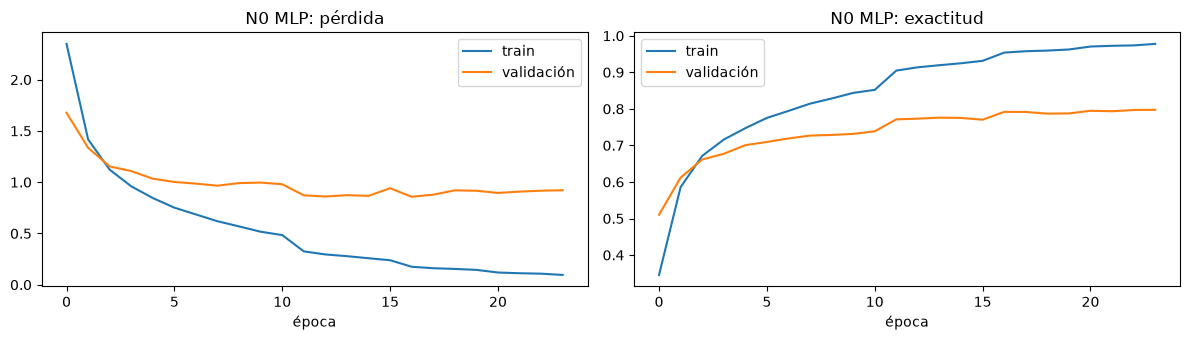

In [6]:
h0 = entrenar_y_evaluar(
    "N0 MLP", "n0_mlp", lr=3e-4, run_id="n0_mlp_b128_lr3e4"
)
graficar_historia(h0, "N0 MLP")


# Etapa 3 — CNN y CRNN para audio

<!-- Descripción de la etapa: completar -->


## 3.x Entrenamiento de CNN y CRNN

Se entrenan las redes con `entrenar_y_evaluar`, una por una.


Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n1_cnn_min --batch 128 --lr 0.0003 --run-id n1_cnn_min_b128_lr3e4 --epochs 60
Epoch 1/60
662/662 - 58s - 88ms/step - accuracy: 0.3021 - loss: 2.5978 - val_accuracy: 0.4010 - val_loss: 2.2179 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 43s - 65ms/step - accuracy: 0.4489 - loss: 2.0554 - val_accuracy: 0.4482 - val_loss: 2.0526 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 43s - 65ms/step - accuracy: 0.5167 - loss: 1.8197 - val_accuracy: 0.4700 - val_loss: 1.9572 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 43s - 66ms/step - accuracy: 0.5751 - loss: 1.6208 - val_accuracy: 0.4808 - val_loss: 1.9112 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 44s - 66ms/step - accuracy: 0.6238 - loss: 1.4487 - val_accuracy: 0.5081 - val_loss: 1.8220 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 44s - 66ms/step - accuracy: 0.6687 - loss: 1.2928 - val_accuracy: 0.4961 - val_loss: 1.8484 - lea

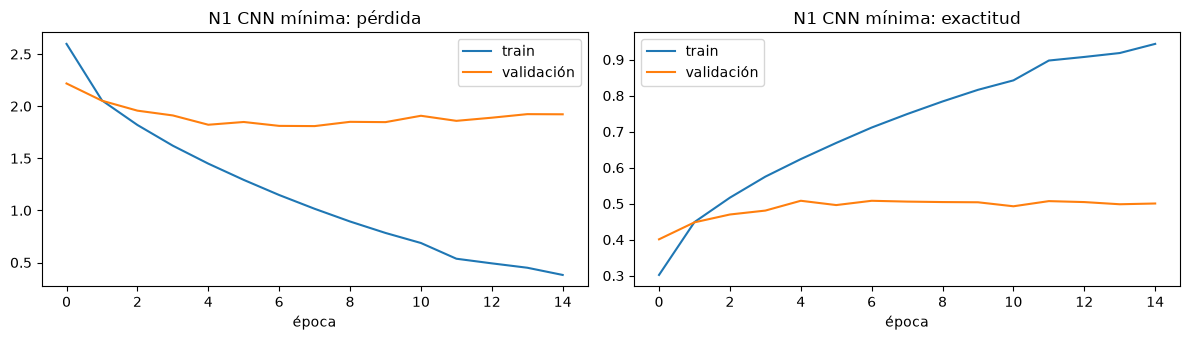

In [7]:
h1 = entrenar_y_evaluar(
    "N1 CNN mínima", "n1_cnn_min", lr=3e-4, run_id="n1_cnn_min_b128_lr3e4"
)
graficar_historia(h1, "N1 CNN mínima")


In [8]:
h2_flat = entrenar_y_evaluar(
    "N2 Flatten", "n2_cnn", lr=3e-4, run_id="n2_cnn_b128_lr3e4"
)


Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n2_cnn --batch 128 --lr 0.0003 --run-id n2_cnn_b128_lr3e4 --epochs 60
Epoch 1/60


E0000 00:00:1794519645.300960 1680357 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794519647.851018 1680357 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794519660.042176 1680357 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794519662.391074 1680357 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


662/662 - 70s - 106ms/step - accuracy: 0.1944 - loss: 2.9234 - val_accuracy: 0.4375 - val_loss: 2.0493 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 48s - 72ms/step - accuracy: 0.3875 - loss: 2.0691 - val_accuracy: 0.6127 - val_loss: 1.4129 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 48s - 73ms/step - accuracy: 0.4836 - loss: 1.7044 - val_accuracy: 0.6861 - val_loss: 1.1485 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 47s - 72ms/step - accuracy: 0.5308 - loss: 1.5121 - val_accuracy: 0.7143 - val_loss: 1.0251 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 47s - 71ms/step - accuracy: 0.5639 - loss: 1.3951 - val_accuracy: 0.7404 - val_loss: 0.9314 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 47s - 70ms/step - accuracy: 0.5901 - loss: 1.3037 - val_accuracy: 0.7556 - val_loss: 0.8638 - learning_rate: 3.0000e-04
Epoch 7/60
662/662 - 44s - 67ms/step - accuracy: 0.6078 - loss: 1.2372 - val_accuracy: 0.7771 - val_loss: 0.7991 - learning_rate: 3.0000e-04
Epoch 8/60
662/662 - 43

In [9]:
h2_gap = entrenar_y_evaluar(
    "N2 GAP", "n2_gap", lr=3e-4, run_id="n2_gap_b128_lr3e4"
)


Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n2_gap --batch 128 --lr 0.0003 --run-id n2_gap_b128_lr3e4 --epochs 60
Epoch 1/60


E0000 00:00:1794521053.334560 1694449 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521055.576480 1694449 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521066.261839 1694449 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794521067.902943 1694449 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


662/662 - 63s - 95ms/step - accuracy: 0.0587 - loss: 3.4763 - val_accuracy: 0.0914 - val_loss: 3.3650 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 44s - 66ms/step - accuracy: 0.0981 - loss: 3.3153 - val_accuracy: 0.1204 - val_loss: 3.2227 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 44s - 66ms/step - accuracy: 0.1159 - loss: 3.2067 - val_accuracy: 0.1291 - val_loss: 3.1353 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 44s - 66ms/step - accuracy: 0.1347 - loss: 3.1085 - val_accuracy: 0.1634 - val_loss: 3.0186 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 43s - 65ms/step - accuracy: 0.1530 - loss: 3.0233 - val_accuracy: 0.1813 - val_loss: 2.9445 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 43s - 65ms/step - accuracy: 0.1675 - loss: 2.9489 - val_accuracy: 0.1997 - val_loss: 2.8468 - learning_rate: 3.0000e-04
Epoch 7/60
662/662 - 43s - 65ms/step - accuracy: 0.1849 - loss: 2.8730 - val_accuracy: 0.2173 - val_loss: 2.7786 - learning_rate: 3.0000e-04
Epoch 8/60
662/662 - 43s

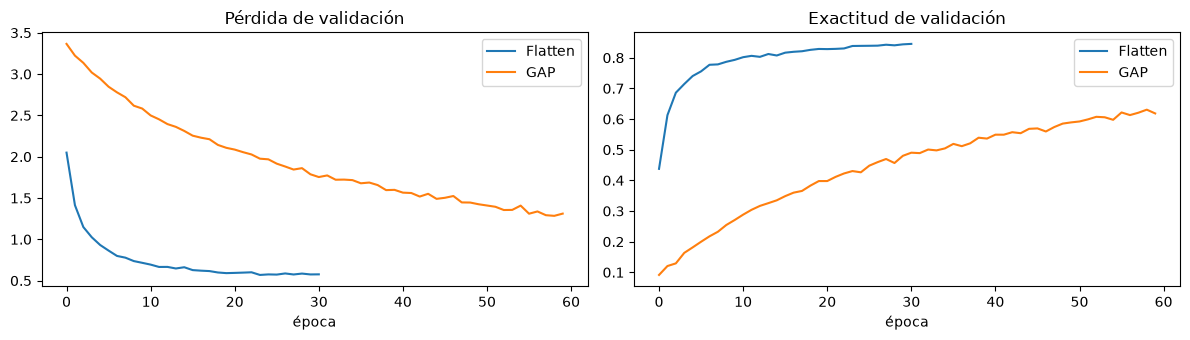

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for nombre, h in [("Flatten", h2_flat), ("GAP", h2_gap)]:
    ax[0].plot(h.history["val_loss"], label=nombre)
    ax[1].plot(h.history["val_accuracy"], label=nombre)
ax[0].set_title("Pérdida de validación"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].set_title("Exactitud de validación"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n3_cnn --batch 128 --lr 0.0003 --run-id n3_cnn_b128_lr3e4 --epochs 60
Epoch 1/60


E0000 00:00:1794523701.534635 1719927 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794523703.842214 1719927 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794523716.522836 1719926 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794523718.126577 1719926 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


662/662 - 69s - 103ms/step - accuracy: 0.0600 - loss: 3.4734 - val_accuracy: 0.0915 - val_loss: 3.3320 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 46s - 69ms/step - accuracy: 0.0736 - loss: 3.3430 - val_accuracy: 0.1156 - val_loss: 3.1756 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 46s - 69ms/step - accuracy: 0.0819 - loss: 3.2445 - val_accuracy: 0.1472 - val_loss: 3.0323 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 46s - 69ms/step - accuracy: 0.0929 - loss: 3.1868 - val_accuracy: 0.1494 - val_loss: 3.0449 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 46s - 70ms/step - accuracy: 0.0950 - loss: 3.1633 - val_accuracy: 0.1631 - val_loss: 2.9496 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 46s - 69ms/step - accuracy: 0.0983 - loss: 3.1403 - val_accuracy: 0.1684 - val_loss: 2.8997 - learning_rate: 3.0000e-04
Epoch 7/60
662/662 - 46s - 70ms/step - accuracy: 0.0984 - loss: 3.1245 - val_accuracy: 0.1638 - val_loss: 2.8732 - learning_rate: 3.0000e-04
Epoch 8/60
662/662 - 47

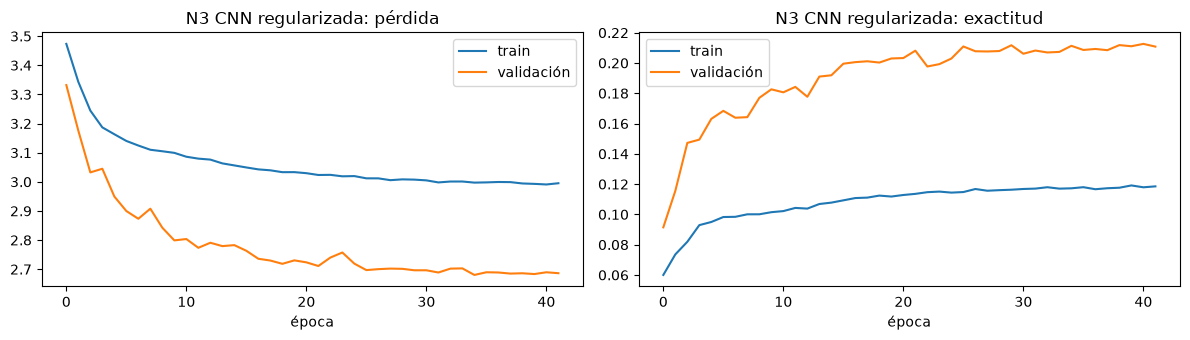

In [11]:
h3 = entrenar_y_evaluar(
    "N3 CNN regularizada", "n3_cnn", lr=3e-4, run_id="n3_cnn_b128_lr3e4"
)
graficar_historia(h3, "N3 CNN regularizada")


Entrenando en subproceso: /home/juan/miniconda3/envs/speech_cmd/bin/python train_model.py --modelo n4_crnn --batch 128 --lr 0.0003 --run-id n4_crnn_b128_lr3e4 --epochs 60
Epoch 1/60


E0000 00:00:1794525779.028691 1741386 gpu_cudamallocasync_allocator.cc:359] gpu_async_0 cuMemAllocAsync failed to allocate 3326083072 bytes: RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
 Reported by CUDA: Free memory/Total memory: 1089404928/3894083584
E0000 00:00:1794525779.028791 1741386 gpu_cudamallocasync_allocator.cc:364] Stats: Limit:                         2.54GiB
InUse:                       393.37MiB
MaxInUse:                      2.73GiB
NumAllocs:                         422
MaxAllocSize:                  2.28GiB
Reserved:                           0B
PeakReserved:                       0B
LargestFreeBlock:                   0B

E0000 00:00:1794525779.033128 1741386 gpu_cudamallocasync_allocator.cc:68] Histogram of current allocation: (allocation_size_in_bytes, nb_allocation_of_that_sizes), ...;
E0000 00:00:1794525779.033141 1741386 gpu_cudamallocasync_allocator.cc:71] 4, 40
E0000 00:00:1794525779.033149 1741386 gpu_cudamallocasync_allocator.cc:71] 8, 5
E00

662/662 - 112s - 169ms/step - accuracy: 0.4064 - loss: 2.2870 - val_accuracy: 0.7137 - val_loss: 1.2259 - learning_rate: 3.0000e-04
Epoch 2/60
662/662 - 79s - 119ms/step - accuracy: 0.7380 - loss: 1.0371 - val_accuracy: 0.8210 - val_loss: 0.7386 - learning_rate: 3.0000e-04
Epoch 3/60
662/662 - 76s - 115ms/step - accuracy: 0.8091 - loss: 0.7330 - val_accuracy: 0.8529 - val_loss: 0.5755 - learning_rate: 3.0000e-04
Epoch 4/60
662/662 - 74s - 112ms/step - accuracy: 0.8425 - loss: 0.5954 - val_accuracy: 0.8668 - val_loss: 0.4998 - learning_rate: 3.0000e-04
Epoch 5/60
662/662 - 74s - 112ms/step - accuracy: 0.8607 - loss: 0.5145 - val_accuracy: 0.8797 - val_loss: 0.4363 - learning_rate: 3.0000e-04
Epoch 6/60
662/662 - 74s - 112ms/step - accuracy: 0.8759 - loss: 0.4540 - val_accuracy: 0.8891 - val_loss: 0.3958 - learning_rate: 3.0000e-04
Epoch 7/60
662/662 - 74s - 111ms/step - accuracy: 0.8852 - loss: 0.4141 - val_accuracy: 0.8983 - val_loss: 0.3721 - learning_rate: 3.0000e-04
Epoch 8/60
662/6

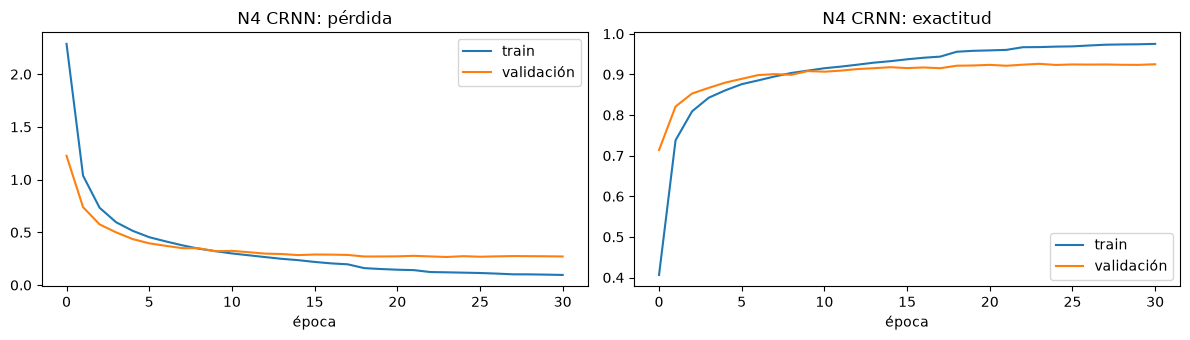

In [12]:
h4 = entrenar_y_evaluar(
    "N4 CRNN", "n4_crnn", lr=3e-4, run_id="n4_crnn_b128_lr3e4"
)
graficar_historia(h4, "N4 CRNN")


## 3.x Comparación end-to-end vs pipeline secuencial

<!-- Completar con la comparación entre CNN/CRNN y el baseline de features + MLP. -->


In [28]:
import glob

filas = [
    json.load(open(f))
    for f in glob.glob(str(DIR_RESULTADOS / "*" / "metricas.json"))
]
pd.DataFrame(filas).sort_values("dev_f1_macro", ascending=False)


,run_id,modelo,params,batch,lr,seed,seg,epocas_entrenadas,dev_f1_macro,dev_f1_weighted,dev_accuracy,dev_accuracy_palabras,features
4,n4_crnn_b128_lr3e4,n4_crnn,413172,128.0,0.0003,42.0,2358.132978,31.0,0.919968,0.925927,0.926013,0.926013,NaN
1,n2_cnn_b128_lr3e4,n2_cnn,943204,128.0,0.0003,42.0,1387.397978,31.0,0.826593,0.837665,0.838420,0.838420,NaN
2,n0_mlp_b128_lr3e4,n0_mlp,8196004,128.0,0.0003,42.0,1186.258891,24.0,0.783966,0.791490,0.791741,0.791741,NaN
7,n2_gap_b128_lr3e4,n2_gap,29796,128.0,0.0003,42.0,2626.282130,60.0,0.608397,0.624301,0.630634,0.630634,NaN
6,logreg_extendido,logreg,2835,NaN,NaN,NaN,32.527235,NaN,0.568225,0.574256,0.576065,0.576065,extendidas
0,n1_cnn_min_b128_lr3e4,n1_cnn_min,1106036,128.0,0.0003,42.0,711.467520,15.0,0.492480,0.501804,0.505764,0.505764,NaN
3,logreg_basico,logreg,560,NaN,NaN,NaN,6.137094,NaN,0.240865,0.250383,0.259851,0.259851,basicas
5,n3_cnn_b128_lr3e4,n3_cnn,943540,128.0,0.0003,42.0,1983.306198,42.0,0.114389,0.147705,0.211329,0.211329,NaN


## 3.x Atribución de errores

<!-- Analizar las matrices de confusión y comparar los errores del end-to-end contra el pipeline secuencial. -->


n0_mlp_b128_lr3e4


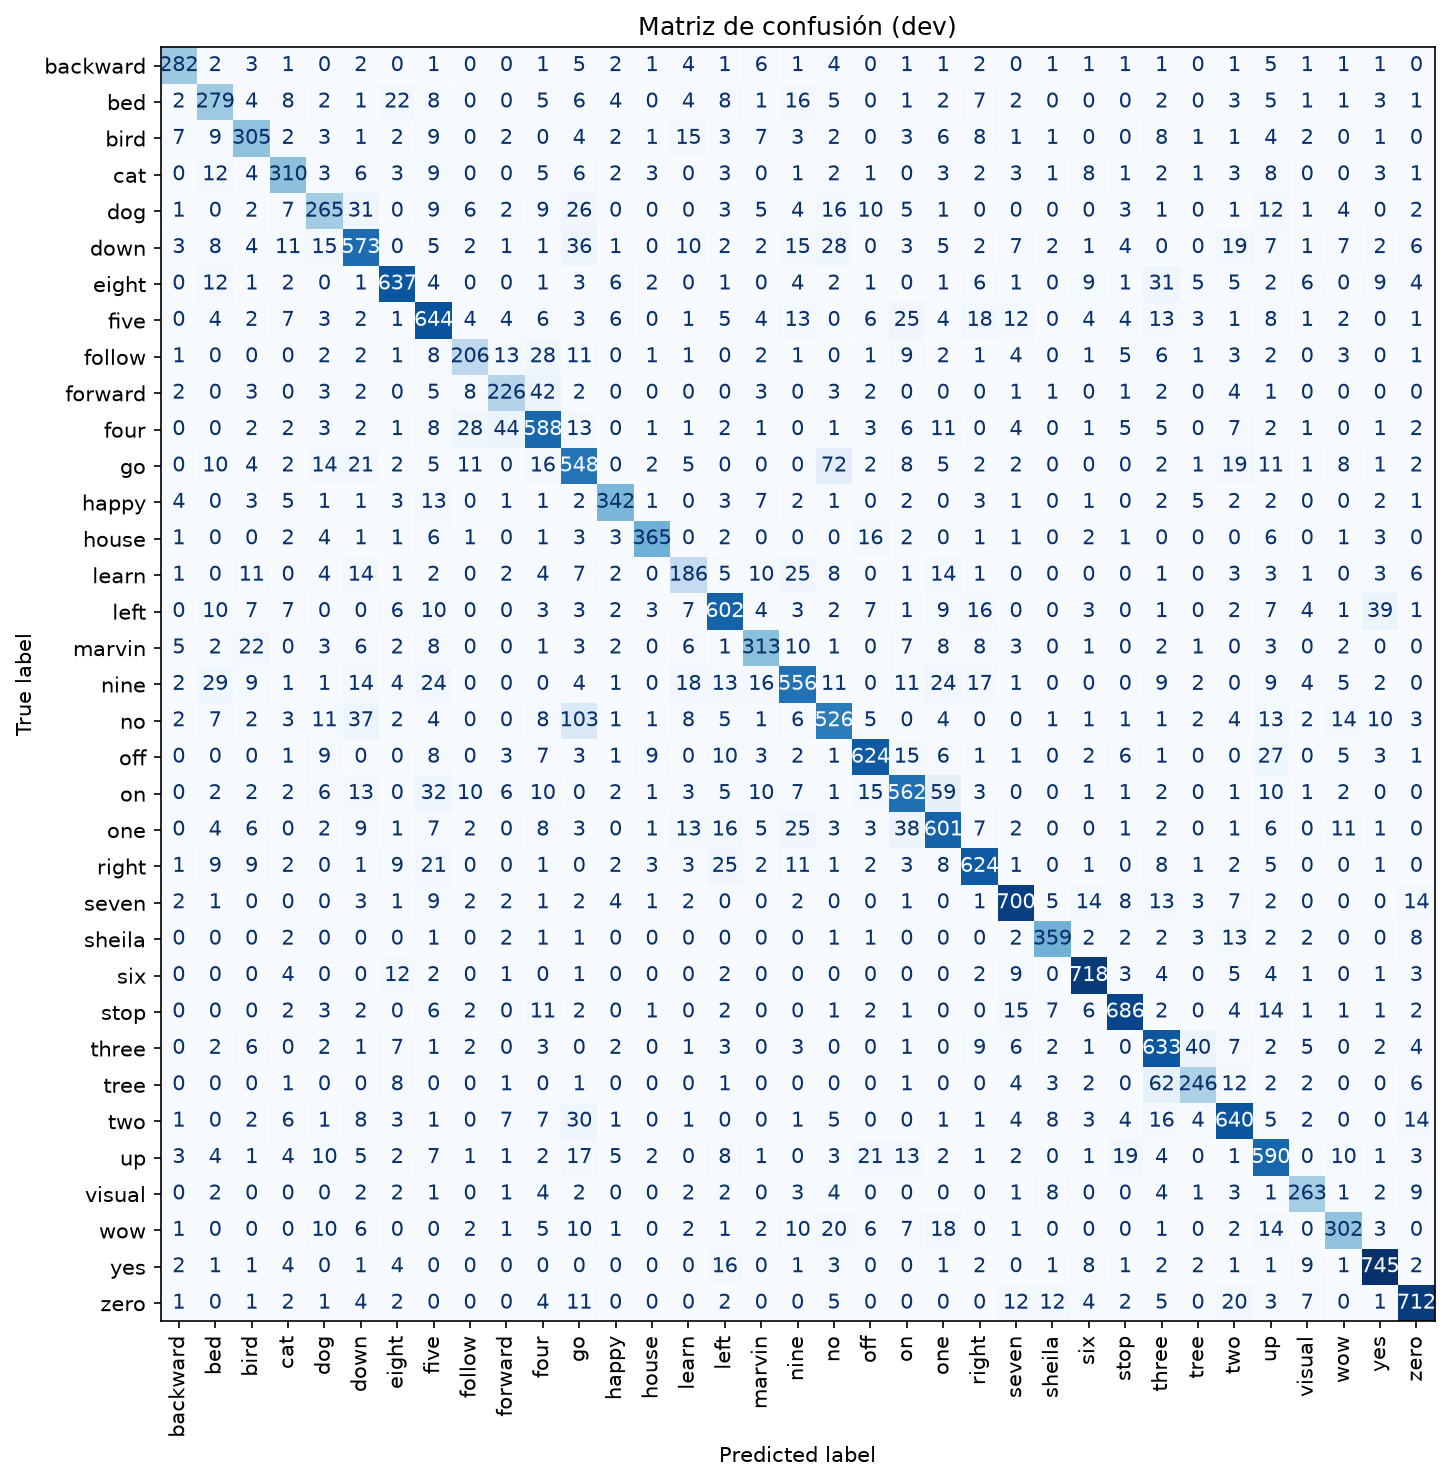

n1_cnn_min_b128_lr3e4


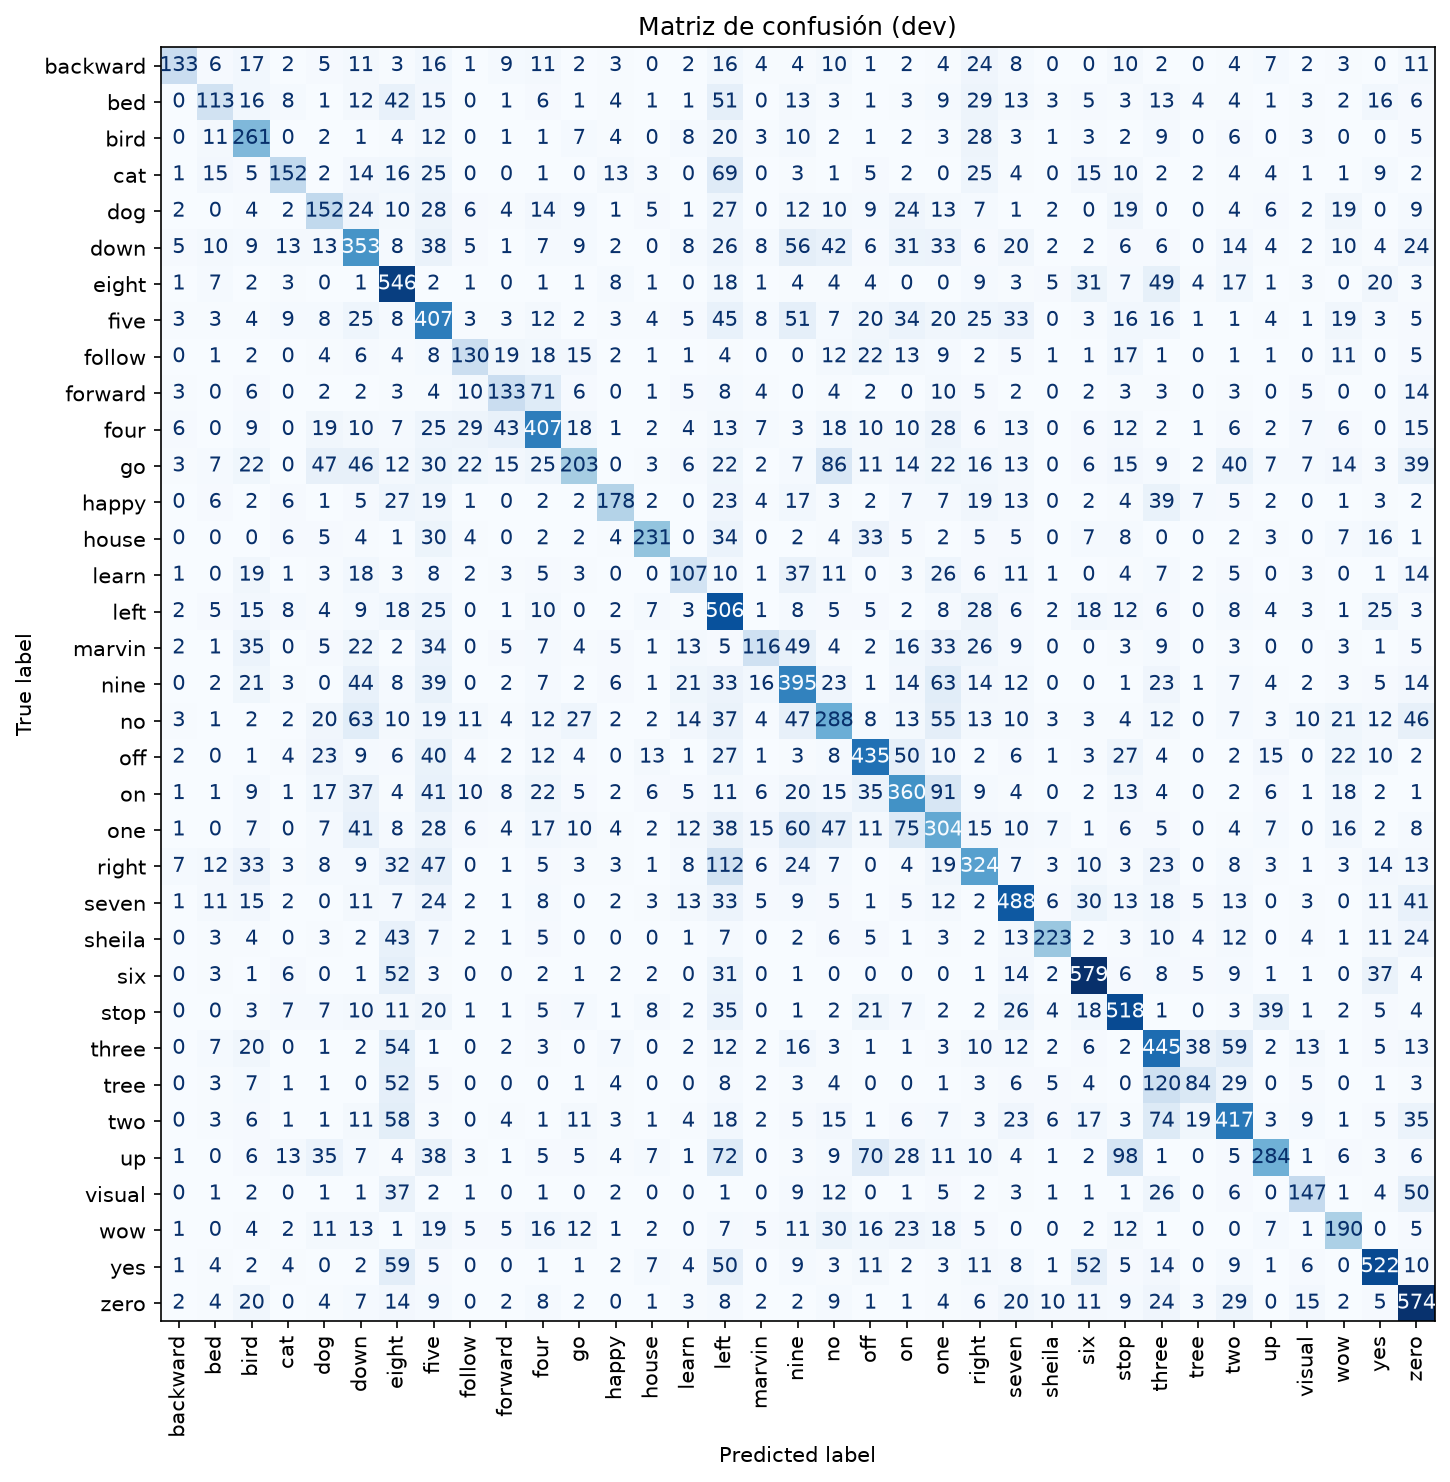

n2_cnn_b128_lr3e4


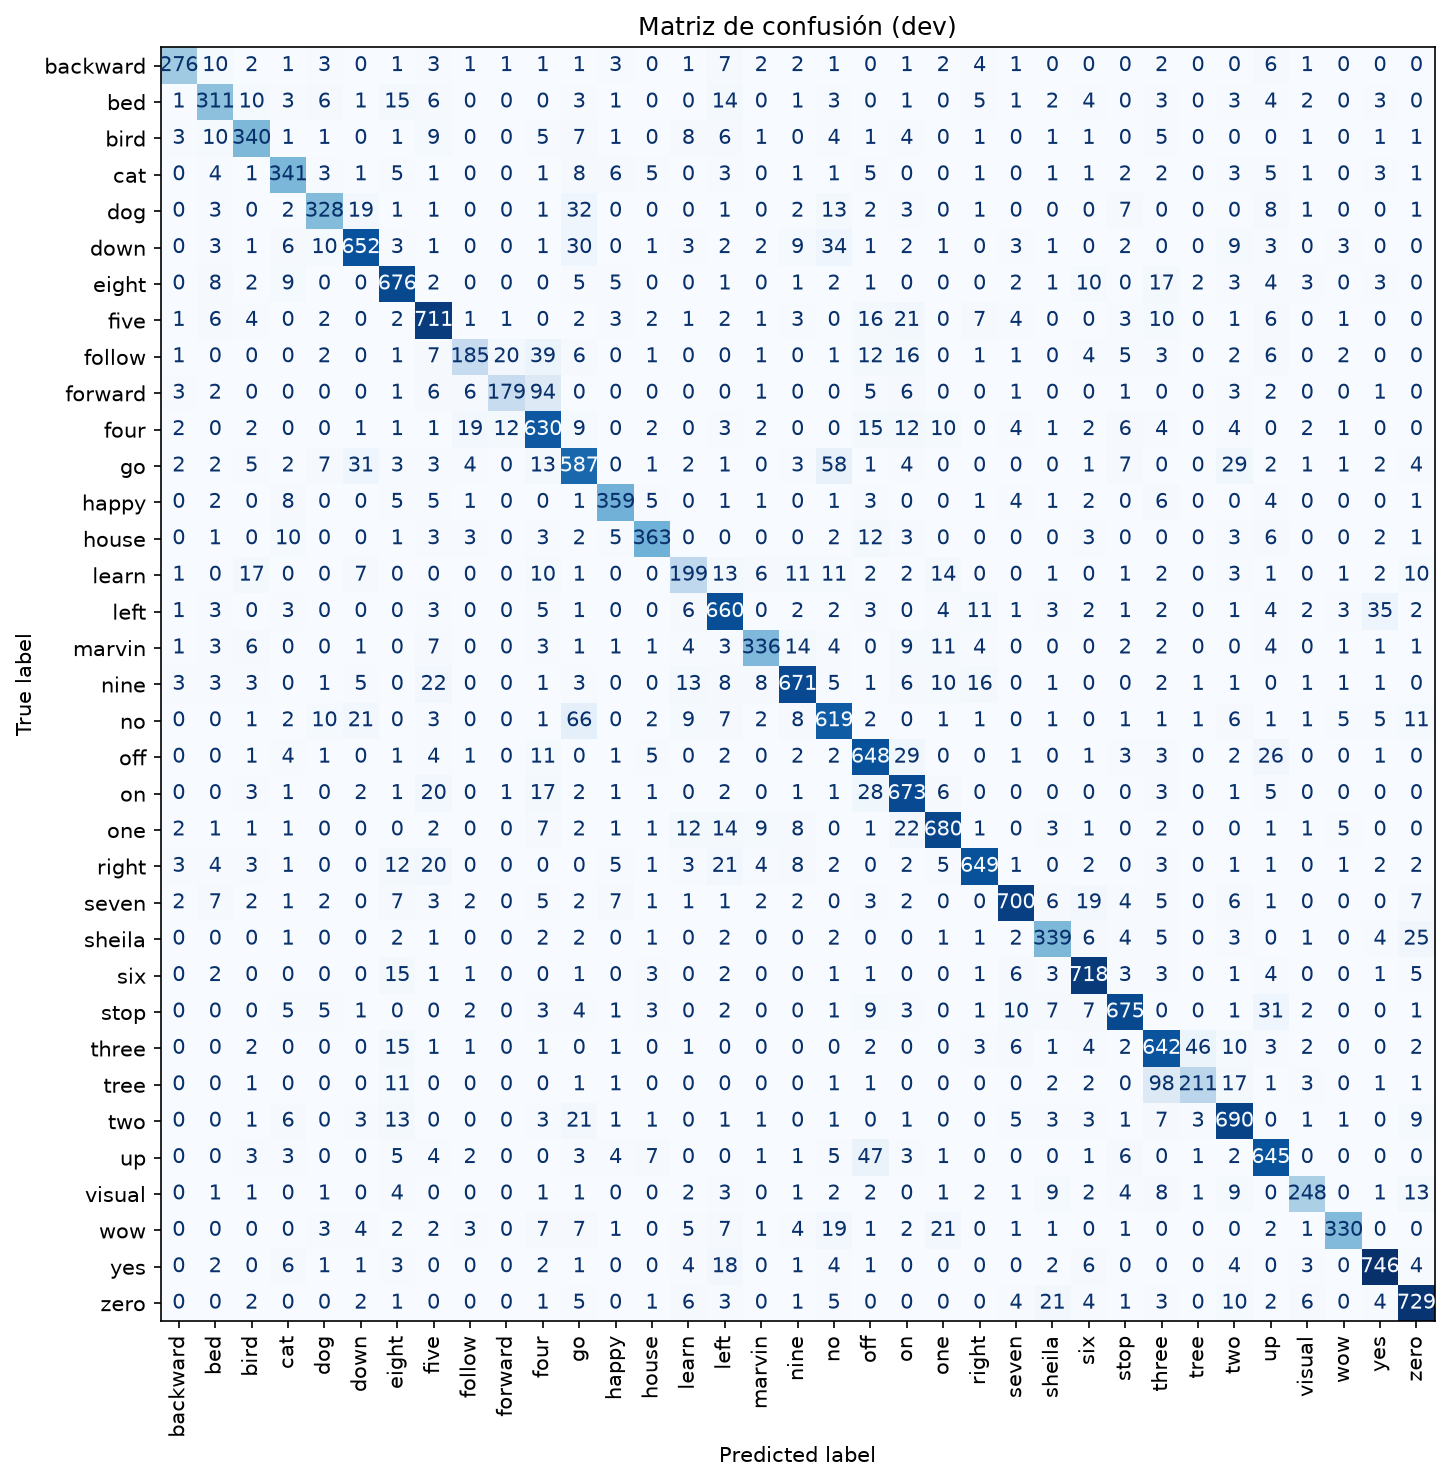

n2_gap_b128_lr3e4


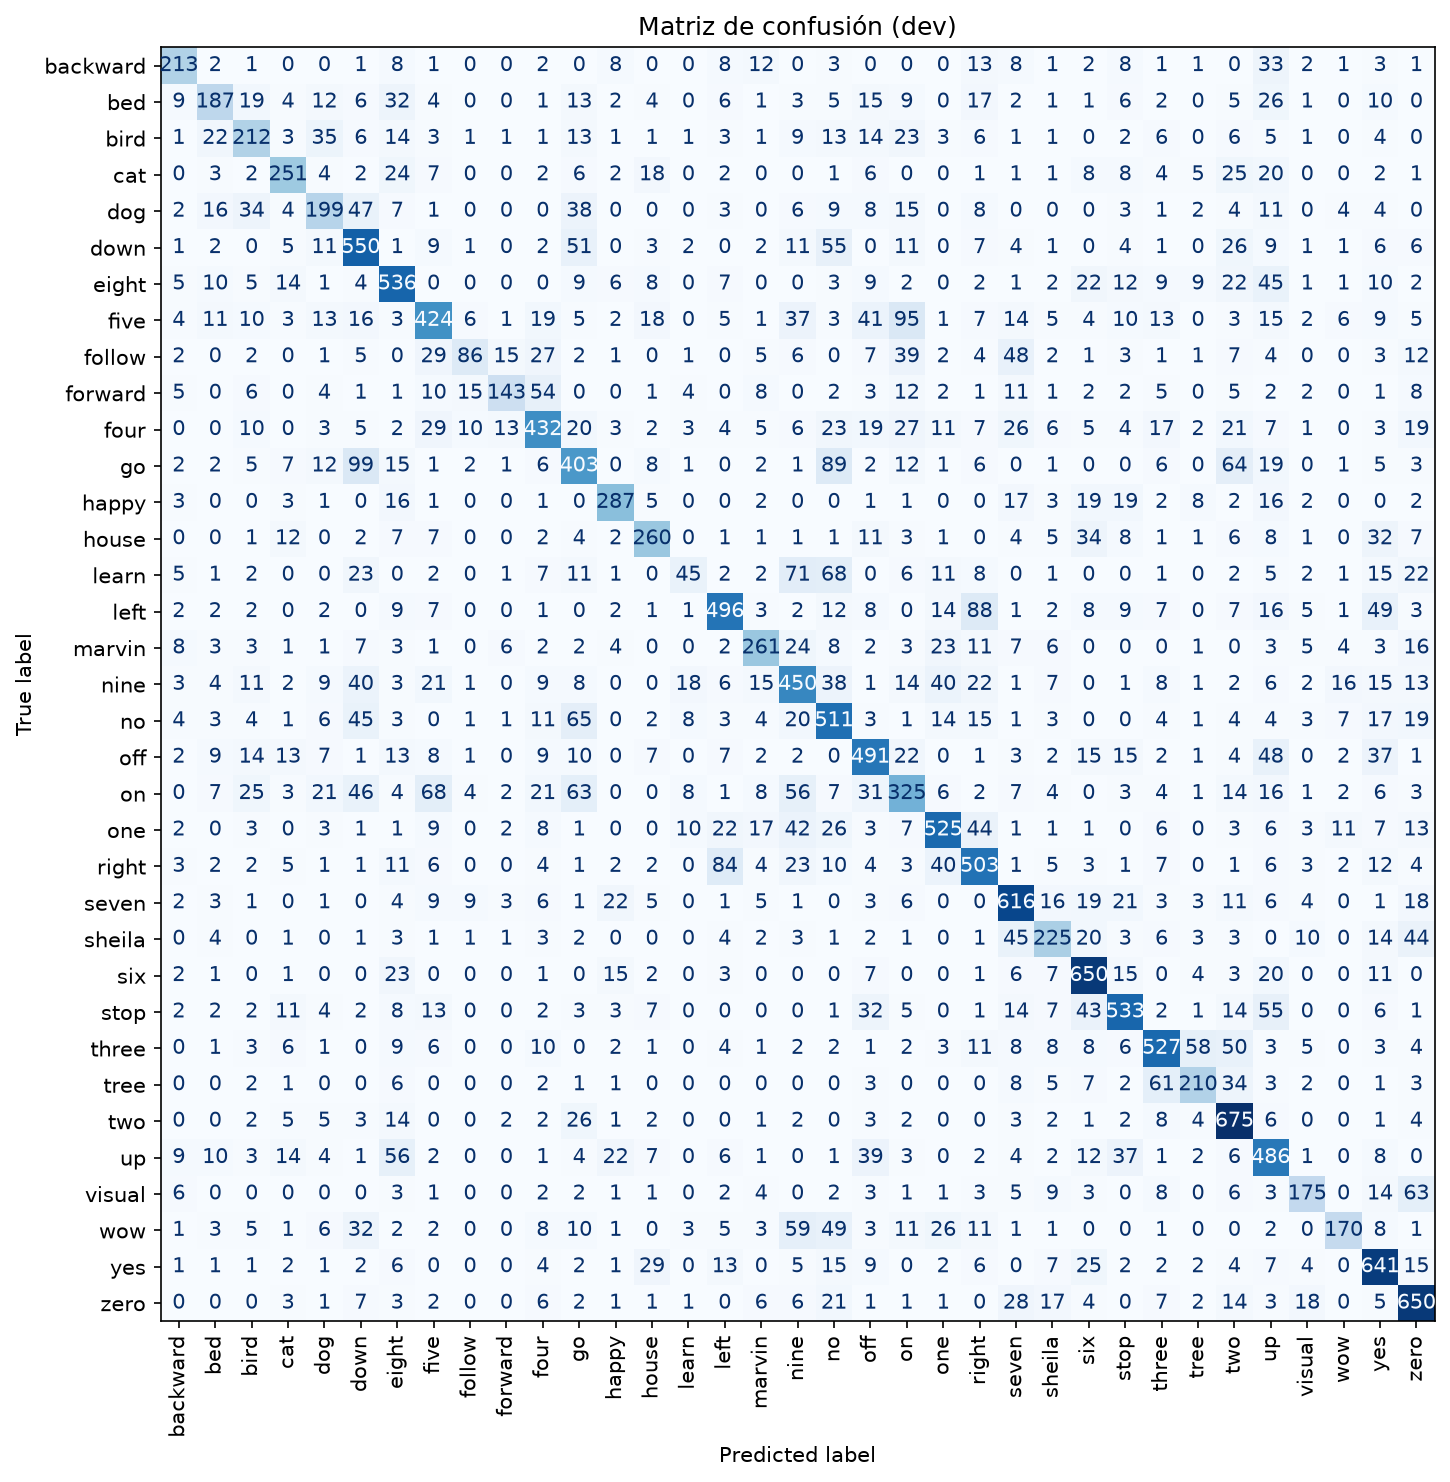

n3_cnn_b128_lr3e4


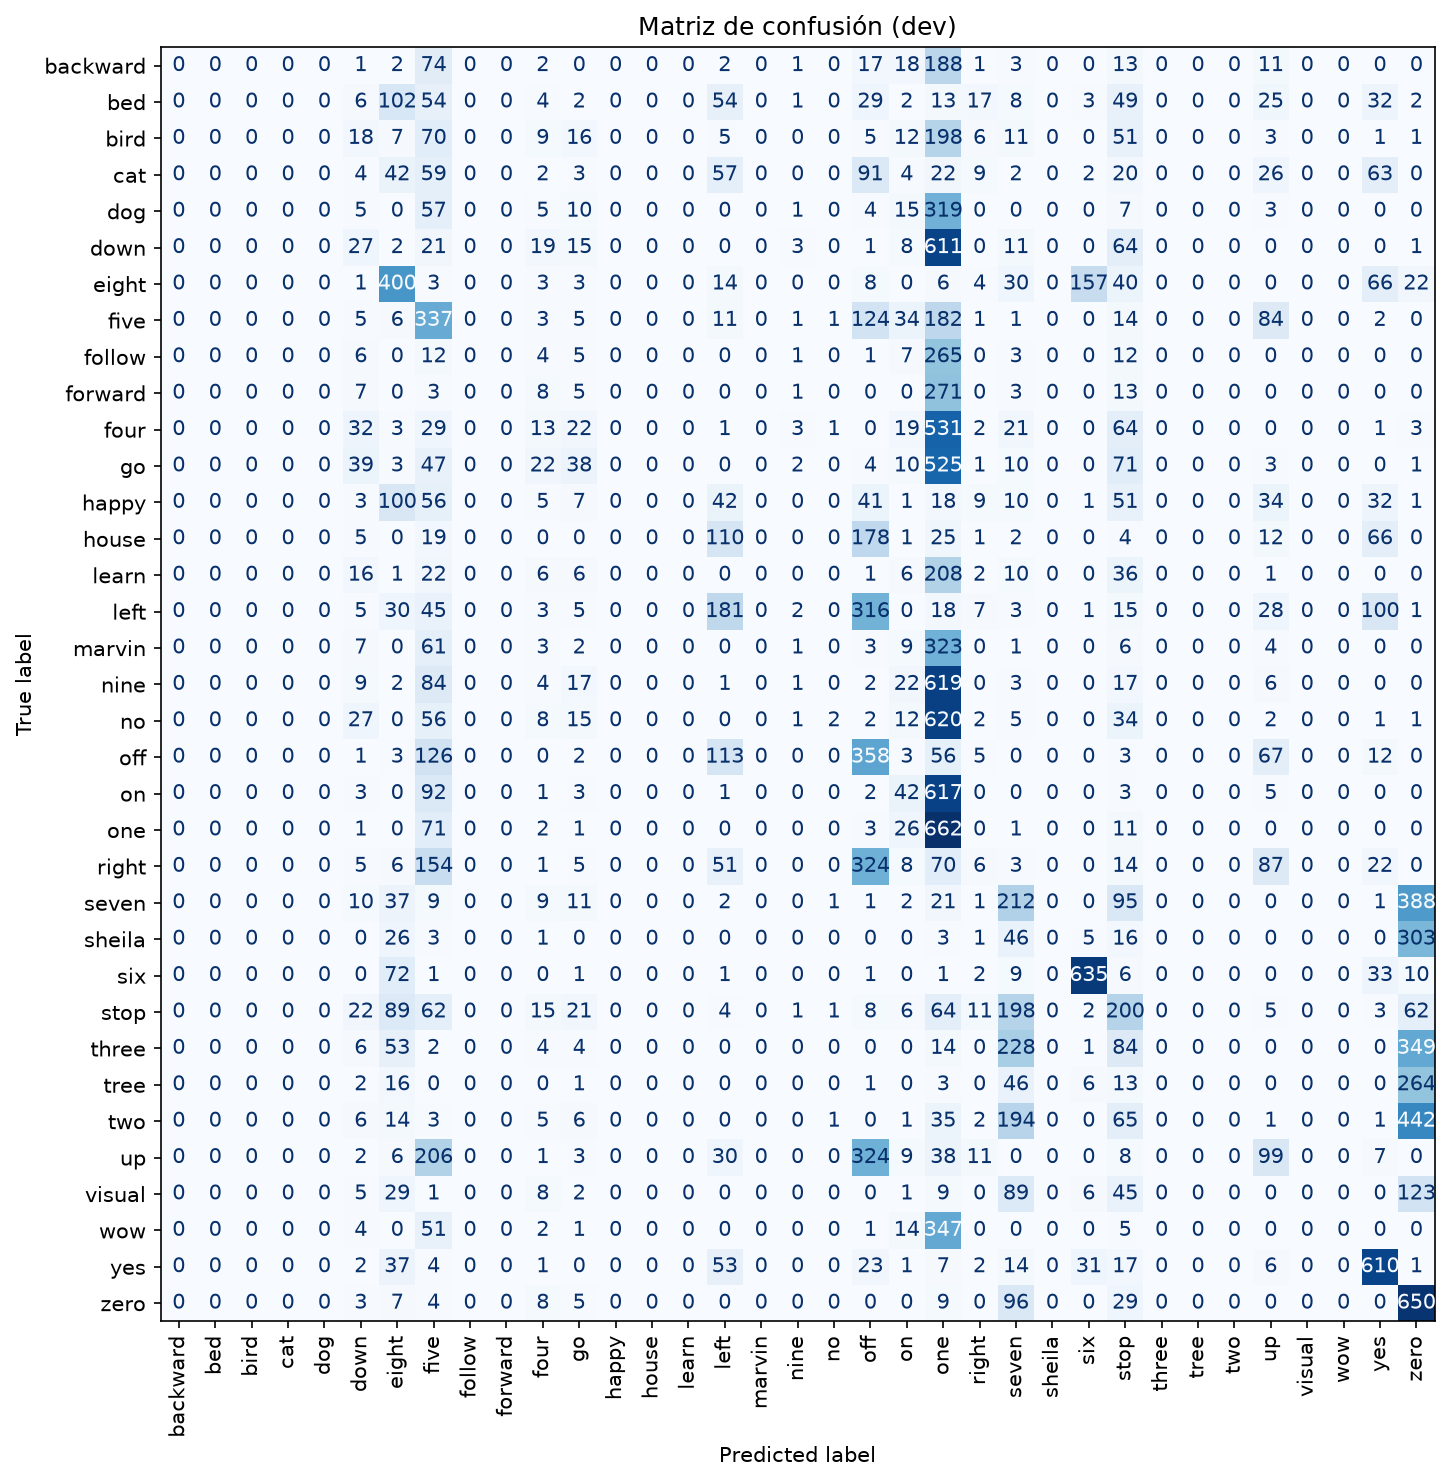

n4_crnn_b128_lr3e4


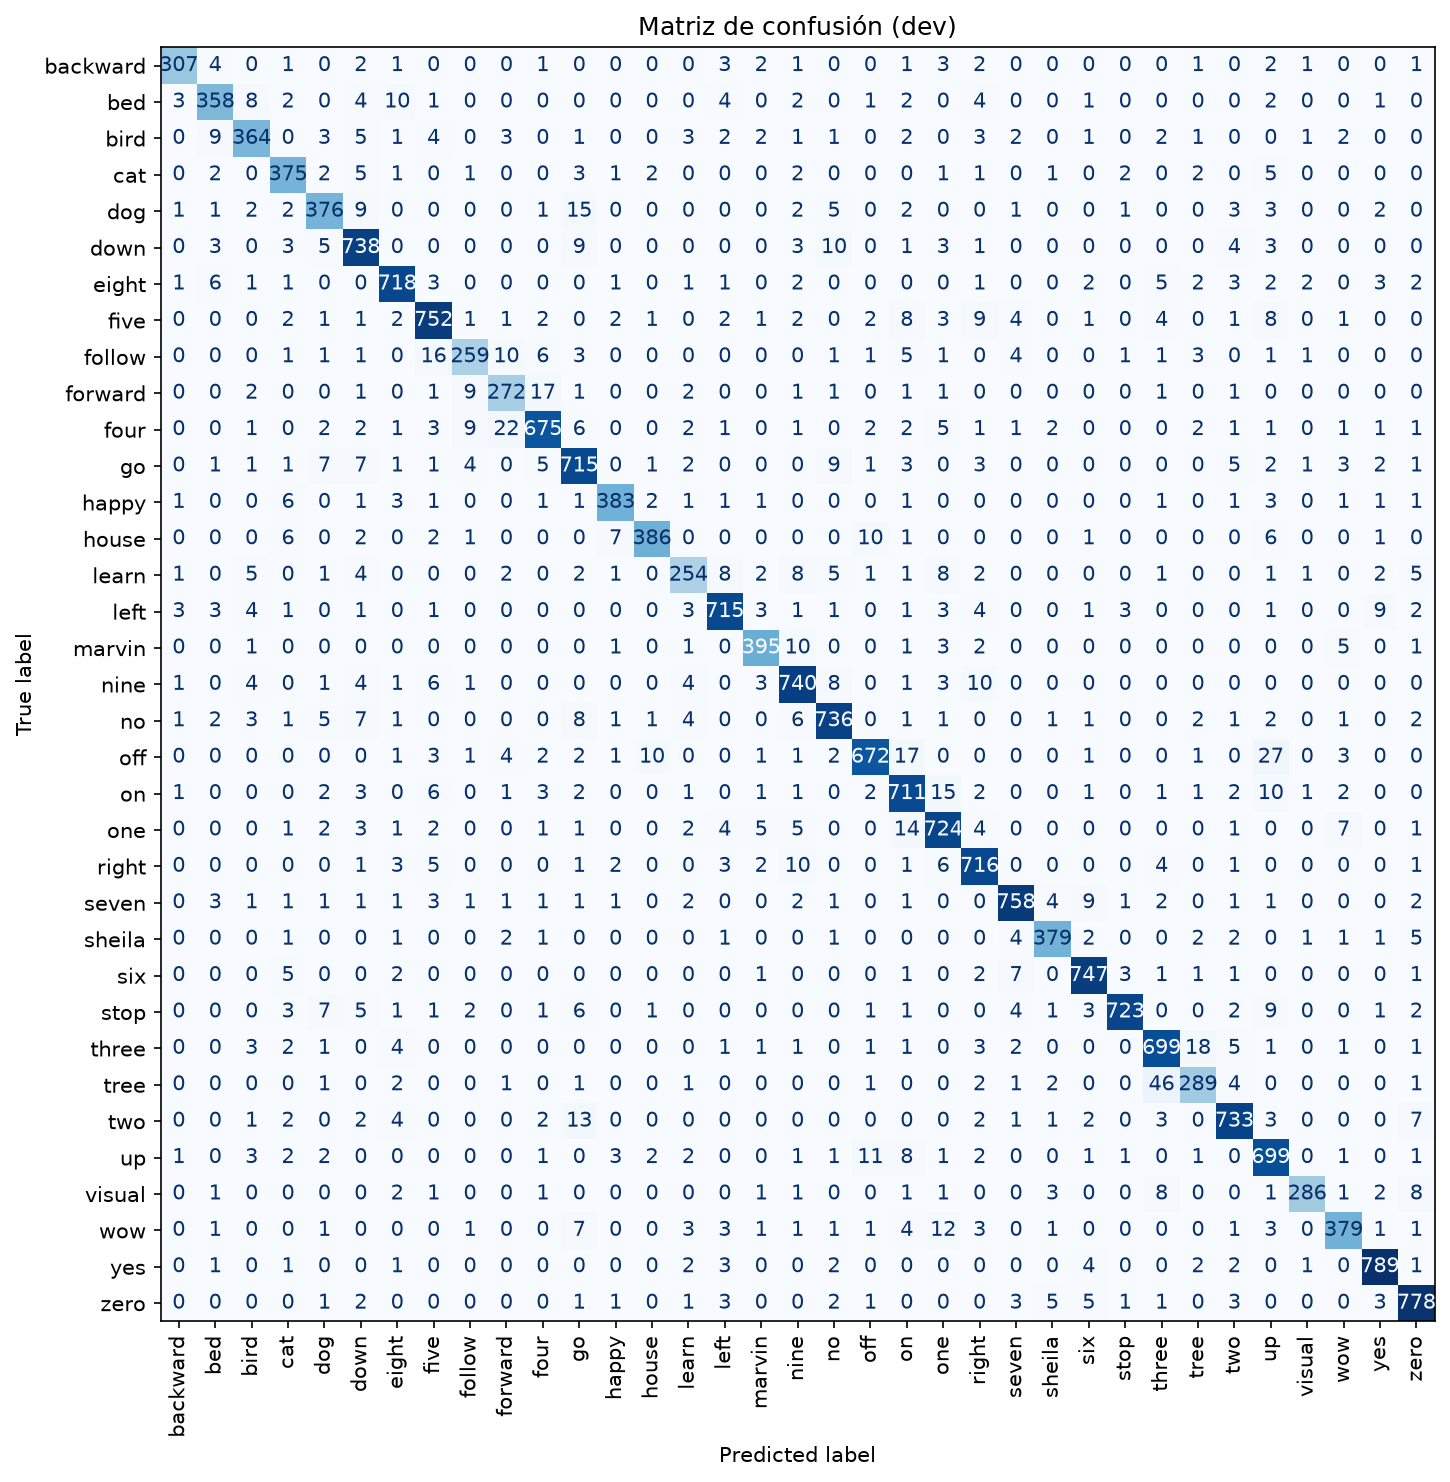

In [14]:
from IPython.display import Image, display

for p in sorted(DIR_RESULTADOS.glob("*/confusion_matrix_dev.png")):
    print(p.parent.name)
    display(Image(filename=str(p)))


### Interpretación de la Etapa 3

<!-- Escribir acá la interpretación -->


# Etapa 4 — Modelo generativo (optativo)

<!-- Descripción de la etapa: completar -->


## 4.x VAE o GAN

<!-- Si se implementa, agregar arquitectura, entrenamiento, espacio latente y métricas. -->


# Etapa 5 — Comparación, test final, sesgos y conclusiones

<!-- Descripción de la etapa: completar -->


## 5.x Tabla comparativa


In [29]:
filas = [
    json.load(open(f))
    for f in glob.glob(str(DIR_RESULTADOS / "*" / "metricas.json"))
]
tabla = pd.DataFrame(filas).sort_values("dev_f1_macro", ascending=False)
display(tabla)


,run_id,modelo,params,batch,lr,seed,seg,epocas_entrenadas,dev_f1_macro,dev_f1_weighted,dev_accuracy,dev_accuracy_palabras,features
4,n4_crnn_b128_lr3e4,n4_crnn,413172,128.0,0.0003,42.0,2358.132978,31.0,0.919968,0.925927,0.926013,0.926013,NaN
1,n2_cnn_b128_lr3e4,n2_cnn,943204,128.0,0.0003,42.0,1387.397978,31.0,0.826593,0.837665,0.838420,0.838420,NaN
2,n0_mlp_b128_lr3e4,n0_mlp,8196004,128.0,0.0003,42.0,1186.258891,24.0,0.783966,0.791490,0.791741,0.791741,NaN
7,n2_gap_b128_lr3e4,n2_gap,29796,128.0,0.0003,42.0,2626.282130,60.0,0.608397,0.624301,0.630634,0.630634,NaN
6,logreg_extendido,logreg,2835,NaN,NaN,NaN,32.527235,NaN,0.568225,0.574256,0.576065,0.576065,extendidas
0,n1_cnn_min_b128_lr3e4,n1_cnn_min,1106036,128.0,0.0003,42.0,711.467520,15.0,0.492480,0.501804,0.505764,0.505764,NaN
3,logreg_basico,logreg,560,NaN,NaN,NaN,6.137094,NaN,0.240865,0.250383,0.259851,0.259851,basicas
5,n3_cnn_b128_lr3e4,n3_cnn,943540,128.0,0.0003,42.0,1983.306198,42.0,0.114389,0.147705,0.211329,0.211329,NaN


### Interpretación de la tabla comparativa

<!-- Escribir acá la interpretación y el trade-off complejidad/performance -->


## 5.x Evaluación final en Test

Se evalúa en Test solamente el modelo elegido en Dev, sin volver a entrenar.


In [25]:
from metricas import calcular_metricas

MEJOR_RUN = "n4_crnn_b128_lr3e4"
MEJOR_MODELO = "n4_crnn"

if MEJOR_MODELO == "logreg":
    if MEJOR_RUN == "logreg_basico":
        modelo_final = modelo_logreg_basico
        X_test_final = X_test_scaled_basico
    elif MEJOR_RUN == "logreg_extendido":
        modelo_final = modelo_logreg_extendido
        X_test_final = X_test_scaled
    else:
        raise ValueError(f"Baseline desconocido: {MEJOR_RUN}")

    with open(DIR_RESULTADOS / MEJOR_RUN / "metricas.json", encoding="utf-8") as f:
        metricas_final = json.load(f)

    metricas_test = calcular_metricas(
        y_test,
        modelo_final.predict(X_test_final),
        modelo_final.classes_,
    )
    metricas_final.update({f"test_{k}": v for k, v in metricas_test.items()})

    with open(
        DIR_RESULTADOS / MEJOR_RUN / "metricas_test.json", "w", encoding="utf-8"
    ) as f:
        json.dump(metricas_final, f, indent=2, ensure_ascii=False)

    print(json.dumps(metricas_final, indent=2, ensure_ascii=False))
else:
    subprocess.run([
        sys.executable, "train_model.py",
        "--modelo", MEJOR_MODELO,
        "--run-id", MEJOR_RUN,
        "--evaluate-only",
        "--test",
    ], check=True, cwd=str(BASE_DIR))


{
  "run_id": "n4_crnn_b128_lr3e4",
  "modelo": "n4_crnn",
  "params": 413172,
  "seg": 0.0,
  "dev_f1_macro": 0.9199683124646323,
  "dev_f1_weighted": 0.925926909201922,
  "dev_accuracy": 0.9260134177454408,
  "dev_accuracy_palabras": 0.9260134177454408,
  "test_f1_macro": 0.8321276828081754,
  "test_f1_weighted": 0.9506170808790079,
  "test_accuracy": 0.8989775051124744,
  "test_accuracy_palabras": 0.9808121374386435,
  "batch": 128,
  "lr": 0.0003,
  "seed": 42,
  "epocas_entrenadas": null
}


In [26]:
with open(DIR_RESULTADOS / MEJOR_RUN / "metricas_test.json", encoding="utf-8") as f:
    display(json.load(f))


{'run_id': 'n4_crnn_b128_lr3e4',
 'modelo': 'n4_crnn',
 'params': 413172,
 'seg': 0.0,
 'dev_f1_macro': 0.9199683124646323,
 'dev_f1_weighted': 0.925926909201922,
 'dev_accuracy': 0.9260134177454408,
 'dev_accuracy_palabras': 0.9260134177454408,
 'test_f1_macro': 0.8321276828081754,
 'test_f1_weighted': 0.9506170808790079,
 'test_accuracy': 0.8989775051124744,
 'test_accuracy_palabras': 0.9808121374386435,
 'batch': 128,
 'lr': 0.0003,
 'seed': 42,
 'epocas_entrenadas': None}

## 5.x Split por hablante

Pendiente de implementación.


## 5.x Análisis

<!-- Analizar sesgos del dataset y el desempeño por subgrupos. -->


In [23]:
for p in sorted(DIR_RESULTADOS.glob("*/classification_report_dev.txt")):
    print("=" * 80)
    print(p.parent.name)
    print(p.read_text(encoding="utf-8"))


n0_mlp_b128_lr3e4
              precision    recall  f1-score   support

    backward       0.87      0.85      0.86       333
         bed       0.68      0.69      0.69       403
        bird       0.73      0.74      0.74       413
         cat       0.78      0.76      0.77       406
         dog       0.70      0.62      0.66       426
        down       0.74      0.73      0.74       783
       eight       0.86      0.84      0.85       757
        five       0.73      0.79      0.76       811
      follow       0.72      0.65      0.68       316
     forward       0.71      0.73      0.72       311
        four       0.75      0.79      0.77       745
          go       0.63      0.71      0.67       776
       happy       0.87      0.83      0.85       411
       house       0.91      0.86      0.89       423
       learn       0.63      0.59      0.61       315
        left       0.80      0.79      0.80       760
      marvin       0.77      0.75      0.76       420
        n

### Interpretación ética y de sesgos

<!-- Escribir acá el análisis -->


## 5.x Conclusiones

<!-- Escribir acá las conclusiones, limitaciones y trabajo futuro. -->
